# Phase 1

## A. Analysis of files and records

In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from scipy.stats import chi2_contingency

In [2]:
directory = Path("180")

files = sorted(file for file in directory.rglob("*") if file.is_file())
countFiles = 0

print("Files type: ")
for file in files:
    print(file.suffix)
    countFiles += 1

print("Number of files: ", countFiles)



Files type: 
.csv
.csv
.csv
Number of files:  3


The dataset has 3 CSV files, each with a different separator (`,`, `;`, `\t`), so `sep` must be set when loading.

In [3]:
gateways = pd.read_csv('180/gateways.csv', sep=';', on_bad_lines='warn')
readings = pd.read_csv('180/readings.csv', sep = r"\t", on_bad_lines='warn', engine='python')
units = pd.read_csv('180/units.csv', on_bad_lines='warn')



In [4]:
gateways.head()

,depot_id,vendor,modelHardware,id_unit,technician,Lon,gatewayId,address_mac,installDate,ipv4,signal_dbm,lastSeen,Lat,firmware_version
0,52,Pinho Lopes Lda.,GWX-200,1739.0,Irina Leal,-6.34286,GW-00000,c0:f5:84:f8:08:41,2024/06/06,188.32.87.90,-65.2,"10/10/2024, 00:00:00",40.57291,v2.7.0
1,113,Christoph GmbH,GWX-100,103.0,Carminho Fonseca,-6.61695,GW-00001,30:db:d5:75:e1:e2,"12/10/2021, 00:00:00",132.117.107.236,-78.7,2024-04-26,39.47290,v1.2.5
2,112,Rädel Löwer AG,GWX-100,13.0,Dr. Marc Robinson,-7.48817,GW-00002,cd:c6:2c:7f:93:2e,2024-04-21,114.142.159.228,-74.9,04 Nov 2024,39.16074,v1.2.5
3,104,Roy and Sons,NODE-9,1344.0,Ryan Rios,-8.59568,GW-00003,d5:03:c8:7c:50:b4,"12/03/2022, 00:00:00",164.198.143.169,-68.3,25 Jan 2025,39.01984,v1.2.5
4,36,Christoph GmbH,GWX-100,1324.0,César da Neto,-9.18714,GW-00004,93:41:75:8f:f1:d5,15 May 2018,65.233.19.254,-52.2,2024-08-06,39.47786,v1.2.5


In [5]:
readings.head()

,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
0,U00193,"08/27/2023, 06:29:00",4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,15.83173,0
1,U00757,2023/11/13,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,11.00633,1
2,U01997,2023-11-26,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,6.20960,0
3,U01633,2023-02-22,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,5.18222,1
4,U00467,"01/23/2023, 03:45:00",3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,6.12806,0


In [6]:
units.head()

,codeFleet,depot_id,hours_service,model_code,line_code,manufacturer,overhaulLast,id_unit,year_commission,region_install,serial_number,ownerOperator,duty_class
0,FA,105,20874.1,XC-7,L6,"Rivers, Welch and Hood","05/06/2023, 00:00:00",1,2019,Christinehaven,AJ-0056-27354,Huhn KGaA,3
1,FA,37,6896.4,XC-7,L4,Walker Ltd,2024-01-15,2,2023,Zerbst,ED-7134-75911,Rädel Löwer AG,heavy
2,FE,36,8193.9,APU-12,L4,Schenk GmbH,2023/01/19,3,2022,Guimarães,AT-0639-19922,Macedo Faria e Filhos,1
3,FB,102,18235.4,APU-20,L6,Silva,2024-03-14,4,2019,Lake Amy,JW-3703-50512,Reinhardt,3
4,FB,11,11350.3,XC-7,L5,Huhn KGaA,2019-05-07,5,2021,Fiães,UC-0462-35464,Leal Freitas S/A,1


In [7]:
units["duty_class"].value_counts()

duty_class
L           253
1           250
light       217
N           170
heavy       163
3           161
med         160
normal      155
2           142
H           138
 L           31
 med         25
 1           24
 heavy       23
 light       22
 N           17
 H           14
 normal      14
 3           12
 2            9
Name: count, dtype: int64

The date attributes (`overhaulLast`, `installDate`, `lastSeen`, `cycleTs`) are stored as text, not `datetime`.
Each of them mixes **4 formats** in roughly equal proportions:
`YYYY-MM-DD`, `YYYY/MM/DD`, `MM/DD/YYYY, hh:mm:ss` and `DD Mon YYYY`.
They will be converted to `datetime` in preprocessing.
duty_class mixes numbers and text (1/2/3, light/normal(med)/heavy, L/N/H).

In [8]:
per_unit = readings.groupby("id_unit").size()
print("readings per unit: mean %.1f, min %d, max %d" % (per_unit.mean(), per_unit.min(), per_unit.max()))
orph = readings[~readings["id_unit"].isin(units["id_unit"])]
print("orphan readings:", len(orph), "rows,", orph["id_unit"].nunique(), "IDs, range", orph["id_unit"].min(), "-", orph["id_unit"].max())
print("gateways with unit:", gateways["id_unit"].notna().sum(), "/", len(gateways))
print("max gateways per unit:", gateways["id_unit"].value_counts().max())

readings per unit: mean 7.3, min 1, max 17
orphan readings: 15572 rows, 2134 IDs, range U00001 - U90497
gateways with unit: 2000 / 16000
max gateways per unit: 1


###  Relationships between files

The files are linked by `id_unit`:

    units ──1:N──► readings
      └────1:1──► gateways

- **units → readings (1:N):** each unit has several readings.
- **units → gateways (1:1):** each unit has one gateway; `depot_id` matches in both files.

**Problems:**
- `id_unit` has a different format in each file (`193`, `193.0`, `U00193`), so it must be normalized.
- 162 readings (IDs U90001–U90497) have no matching unit (orphan records).
- 14,000 of the 16,000 gateways are not linked to any unit.

In [9]:
gateways["id_unit"].head(), readings["id_unit"].head(), units["id_unit"].head()
#data is related with id_unit, this column in both 3 files, the data type of id_unit column in each file is different

(0    1739.0
 1     103.0
 2      13.0
 3    1344.0
 4    1324.0
 Name: id_unit, dtype: float64,
 0    U00193
 1    U00757
 2    U01997
 3    U01633
 4    U00467
 Name: id_unit, dtype: str,
 0    1
 1    2
 2    3
 3    4
 4    5
 Name: id_unit, dtype: int64)

In [10]:
gateways["id_unit"] = gateways["id_unit"].astype("Int64")
units["id_unit"] = units["id_unit"].astype(int)
readings["id_unit"] = readings["id_unit"].astype(str).str.lstrip('U').astype(int)
gateways["id_unit"], readings["id_unit"], units["id_unit"]

(0        1739
 1         103
 2          13
 3        1344
 4        1324
          ... 
 15995    <NA>
 15996    <NA>
 15997    <NA>
 15998    <NA>
 15999    <NA>
 Name: id_unit, Length: 16000, dtype: Int64,
 0         193
 1         757
 2        1997
 3        1633
 4         467
          ... 
 15567    1758
 15568    1552
 15569    1052
 15570    1791
 15571    1290
 Name: id_unit, Length: 15572, dtype: int64,
 0          1
 1          2
 2          3
 3          4
 4          5
         ... 
 1995    1996
 1996    1997
 1997    1998
 1998    1999
 1999    2000
 Name: id_unit, Length: 2000, dtype: int64)

`id_unit` is now an integer in all files (`Int64` in gateways, because it contains 14,000 missing values).

## Structure of the records

In [11]:
gateways.shape, readings.shape, units.shape

((16000, 14), (15572, 13), (2000, 13))

In [12]:
gateways.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   depot_id          16000 non-null  int64  
 1   vendor            16000 non-null  str    
 2   modelHardware     16000 non-null  str    
 3   id_unit           2000 non-null   Int64  
 4   technician        16000 non-null  str    
 5   Lon               16000 non-null  float64
 6   gatewayId         16000 non-null  str    
 7   address_mac       16000 non-null  str    
 8   installDate       16000 non-null  str    
 9   ipv4              16000 non-null  str    
 10  signal_dbm        16000 non-null  float64
 11  lastSeen          16000 non-null  str    
 12  Lat               16000 non-null  float64
 13  firmware_version  16000 non-null  str    
dtypes: Int64(1), float64(3), int64(1), str(9)
memory usage: 1.7 MB


In [13]:
readings.info()

<class 'pandas.DataFrame'>
RangeIndex: 15572 entries, 0 to 15571
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            15572 non-null  int64  
 1   cycleTs            15572 non-null  str    
 2   currentMotor       15572 non-null  float64
 3   dpFilter           14910 non-null  float64
 4   oilTemperature     15572 non-null  float64
 5   reservoirPressure  15572 non-null  float64
 6   pressureOil        15572 non-null  float64
 7   rms_vibration      14950 non-null  float64
 8   flowmeter          15572 non-null  float64
 9   humidity_intake    14780 non-null  float64
 10  noiseAmbient       15572 non-null  float64
 11  dischargeDewpoint  15572 non-null  float64
 12  Failure            15572 non-null  int64  
dtypes: float64(10), int64(2), str(1)
memory usage: 1.5 MB


In [14]:
units.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   codeFleet        2000 non-null   str    
 1   depot_id         2000 non-null   int64  
 2   hours_service    1900 non-null   float64
 3   model_code       2000 non-null   str    
 4   line_code        2000 non-null   str    
 5   manufacturer     2000 non-null   str    
 6   overhaulLast     2000 non-null   str    
 7   id_unit          2000 non-null   int64  
 8   year_commission  2000 non-null   int64  
 9   region_install   2000 non-null   str    
 10  serial_number    2000 non-null   str    
 11  ownerOperator    2000 non-null   str    
 12  duty_class       2000 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 203.3 KB


## Null values and duplicates

In [15]:
readings.isna().sum()

id_unit                0
cycleTs                0
currentMotor           0
dpFilter             662
oilTemperature         0
reservoirPressure      0
pressureOil            0
rms_vibration        622
flowmeter              0
humidity_intake      792
noiseAmbient           0
dischargeDewpoint      0
Failure                0
dtype: int64

In [16]:
gateways.isna().sum()

depot_id                0
vendor                  0
modelHardware           0
id_unit             14000
technician              0
Lon                     0
gatewayId               0
address_mac             0
installDate             0
ipv4                    0
signal_dbm              0
lastSeen                0
Lat                     0
firmware_version        0
dtype: int64

In [17]:
units.isna().sum()

codeFleet            0
depot_id             0
hours_service      100
model_code           0
line_code            0
manufacturer         0
overhaulLast         0
id_unit              0
year_commission      0
region_install       0
serial_number        0
ownerOperator        0
duty_class           0
dtype: int64

In [18]:
gateways.duplicated().sum()

np.int64(0)

In [19]:
readings.duplicated().sum()

np.int64(230)

In [20]:
units.duplicated().sum()

np.int64(0)

`readings` contains 230 exact duplicates, which will be removed in preprocessing.
Missing values in `dpFilter` (662), `rms_vibration` (622), `humidity_intake` (792) and `hours_service` (100)
will be imputed. The 14,000 missing `gateways.id_unit` values are structural (gateways without a unit).

## B. Analysis of individual attributes

We analyze 14 continuous numeric attributes and 1 discrete(year_commission), chosen because they are measured values
whose distribution and valid range can be checked:

- **readings** (sensor measurements): `currentMotor`, `dpFilter`, `oilTemperature`, `reservoirPressure`,
  `pressureOil`, `rms_vibration`, `flowmeter`, `humidity_intake`, `noiseAmbient`, `dischargeDewpoint`
- **gateways** (device location and signal): `Lat`, `Lon`, `signal_dbm`
- **units** (device information): `hours_service`, `year_commission`

count       15572.000000
mean            5.296595
std             3.273052
min             0.266600
25%             3.743080
50%             5.087180
75%             6.663353
max            99.000000
skew           19.601706
kurtosis      558.268098
median          5.087180
Name: currentMotor, dtype: float64

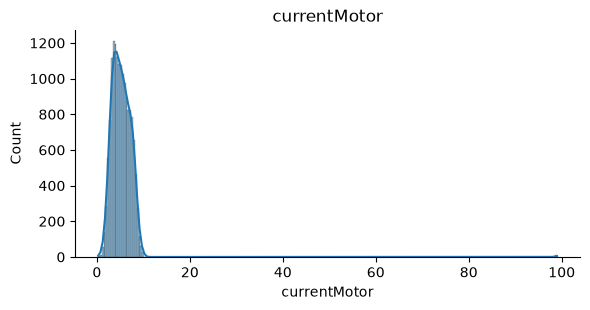

count       14910.000000
mean           24.119032
std            11.502224
min             7.448490
25%            16.329075
50%            21.389575
75%            28.541063
max           120.000000
skew            2.014745
kurtosis        7.194025
median         21.389575
Name: dpFilter, dtype: float64

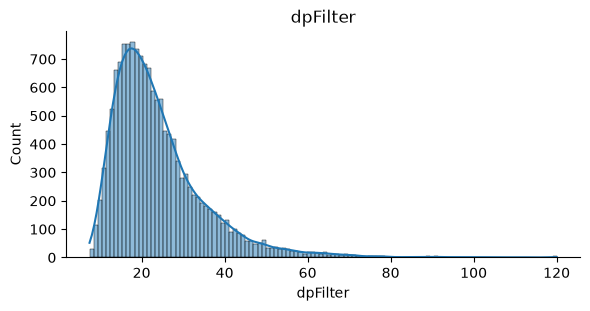

count       15572.000000
mean           51.744591
std            59.647429
min          -999.000000
25%            46.756825
50%            54.967085
75%            63.158803
max            95.000000
skew          -16.847193
kurtosis      293.975859
median         54.967085
Name: oilTemperature, dtype: float64

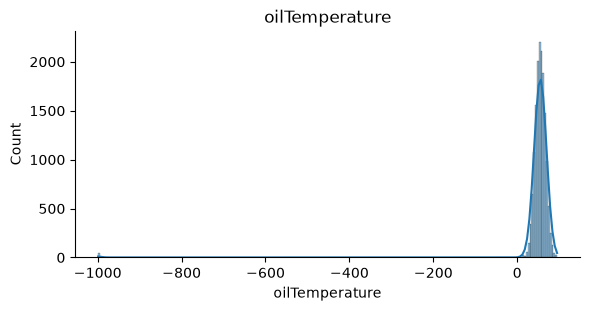

count       15572.000000
mean            8.692845
std             0.598296
min             6.500000
25%             8.285735
50%             8.691360
75%             9.096332
max            10.500000
skew           -0.000892
kurtosis       -0.037602
median          8.691360
Name: reservoirPressure, dtype: float64

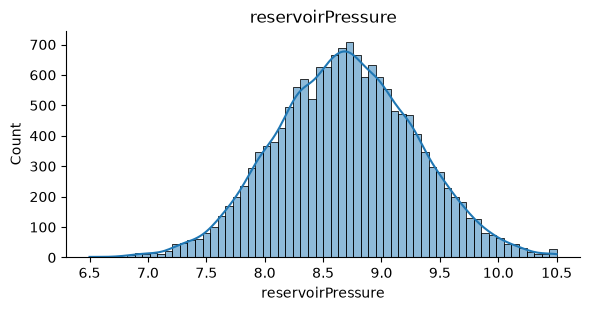

count       15572.000000
mean            3.692293
std             0.561880
min             1.500000
25%             3.311948
50%             3.688170
75%             4.070700
max             5.775210
skew            0.026011
kurtosis       -0.027228
median          3.688170
Name: pressureOil, dtype: float64

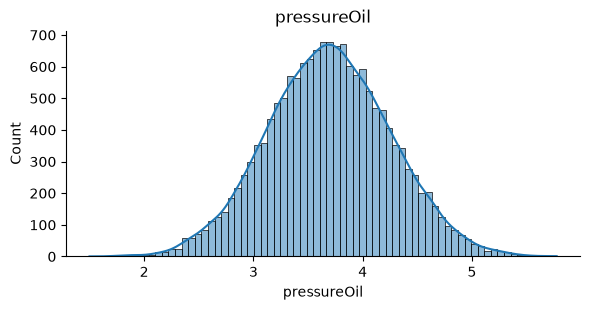

count       14950.000000
mean            3.061109
std             1.628904
min             0.500000
25%             1.925193
50%             2.709255
75%             3.774242
max            14.000000
skew            1.649602
kurtosis        4.473238
median          2.709255
Name: rms_vibration, dtype: float64

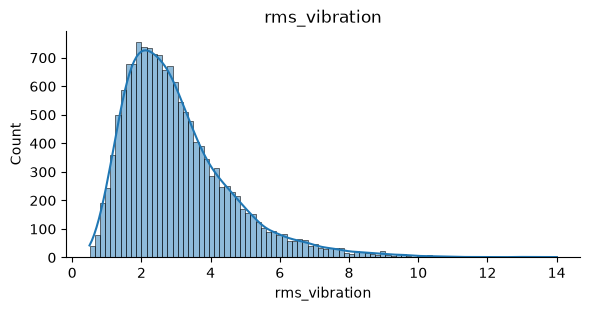

count       15572.000000
mean           28.028240
std             3.956733
min            15.000000
25%            25.348402
50%            28.029065
75%            30.713195
max            40.000000
skew           -0.019540
kurtosis       -0.074550
median         28.029065
Name: flowmeter, dtype: float64

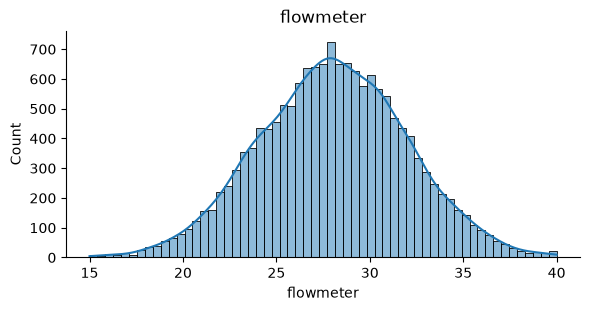

count       14780.000000
mean           52.308947
std            24.458946
min            10.005000
25%            31.194165
50%            52.068300
75%            73.350480
max            94.997260
skew            0.009268
kurtosis       -1.191957
median         52.068300
Name: humidity_intake, dtype: float64

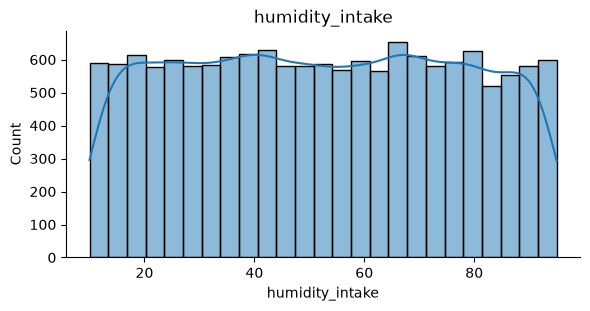

count       15572.000000
mean           74.990066
std             5.994324
min            55.000000
25%            70.977465
50%            74.961685
75%            79.073712
max            95.000000
skew           -0.017156
kurtosis       -0.036102
median         74.961685
Name: noiseAmbient, dtype: float64

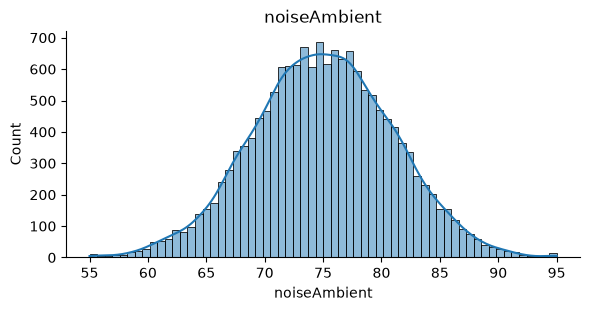

count       15572.000000
mean            8.048645
std             3.502732
min            -4.322190
25%             5.666780
50%             8.013085
75%            10.414853
max            22.421020
skew            0.034431
kurtosis        0.012359
median          8.013085
Name: dischargeDewpoint, dtype: float64

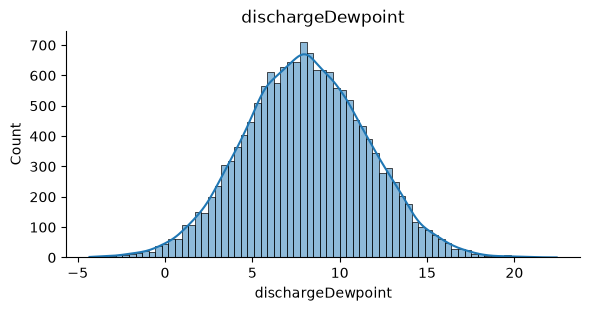

count       16000.000000
mean           40.157236
std             0.889437
min            38.600100
25%            39.390237
50%            40.168405
75%            40.923405
max            41.699630
skew           -0.017412
kurtosis       -1.186647
median         40.168405
Name: Lat, dtype: float64

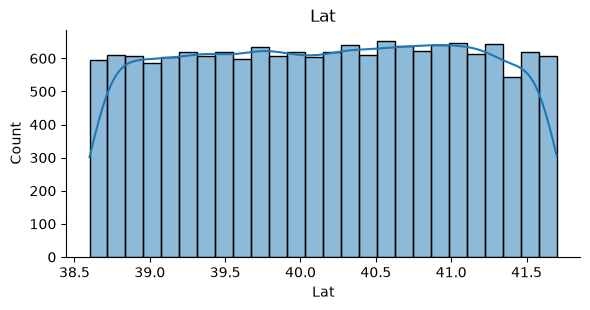

count       16000.000000
mean           -7.747075
std             0.902379
min            -9.299830
25%            -8.534870
50%            -7.737640
75%            -6.963240
max            -6.200030
skew           -0.008257
kurtosis       -1.213274
median         -7.737640
Name: Lon, dtype: float64

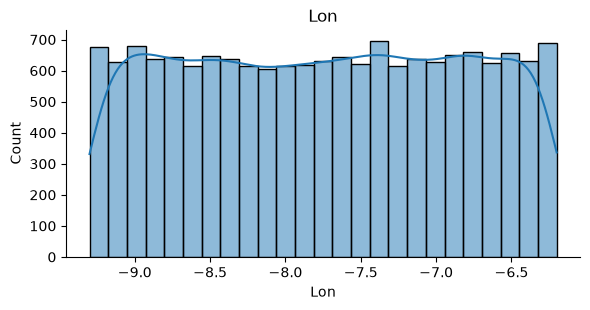

count       16000.000000
mean          -70.009619
std             9.933242
min          -106.100000
25%           -76.700000
50%           -70.200000
75%           -63.100000
max           -40.000000
skew           -0.000390
kurtosis       -0.049539
median        -70.200000
Name: signal_dbm, dtype: float64

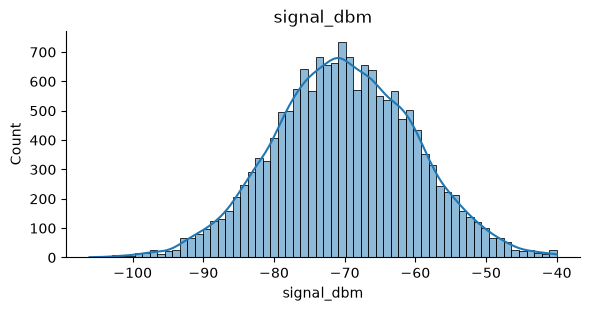

count        1900.000000
mean        14099.588263
std          8596.450754
min          1499.700000
25%          7832.825000
50%         11942.750000
75%         18015.800000
max         45000.000000
skew            1.342653
kurtosis        1.785221
median      11942.750000
Name: hours_service, dtype: float64

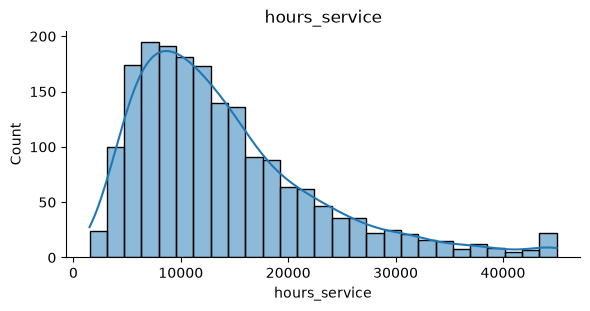

count       2000.000000
mean        2020.456000
std            2.475506
min         2012.000000
25%         2019.000000
50%         2021.000000
75%         2022.000000
max         2024.000000
skew          -1.303710
kurtosis       1.677792
median      2021.000000
Name: year_commission, dtype: float64

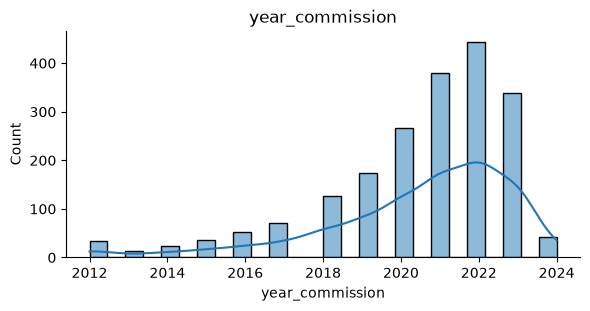

In [21]:
rdngsAtt = ["currentMotor", "dpFilter", "oilTemperature", "reservoirPressure",
  "pressureOil", "rms_vibration", "flowmeter", "humidity_intake", "noiseAmbient", "dischargeDewpoint"]
gtwsAtt = ["Lat", "Lon",
"signal_dbm"]
unitsAtt= ["hours_service", "year_commission"]


def attributeDescription(df, attributes):
    for attribute in attributes:
        desc = df[attribute].describe()
        desc["skew"] = df[attribute].skew()
        desc["kurtosis"] = df[attribute].kurtosis()
        desc["median"] = df[attribute].median()

        display(desc)
        sns.displot(df[attribute].dropna(), kde=True, height=3, aspect=2)
        plt.title(attribute)
        plt.show()

attributeDescription(readings, rdngsAtt)
attributeDescription(gateways, gtwsAtt)
attributeDescription(units, unitsAtt)


**currentMotor** – mean 5.30, median 5.09, std 3.27, range 0.27–99.
Extreme skew (19.6) and kurtosis (558) are caused by 13 values of **99**, a placeholder.
Without them: max 10.0, so a nearly symmetric distribution (skew 0.18)
capped at 10.

**dpFilter** – mean 24.1, median 21.4, std 11.5, range 7.5–120, 662 missing.
**Right-skewed** (skew 2.0, kurtosis 7.2): most values are 15–29 (IQR), with a long tail of high
pressure drops, which indicates clogged filters. The mean is above the median because of the tail.
All values are within the physically plausible range.

**oilTemperature** – mean 51.7, median 55.0, std 59.7, range −999–95.
The statistics are distorted by 48 values of **−999** (placeholder): skew −16.9, std 59.7.
Without them: mean 55.0, median 55.0, std 12.0, skew ≈ 0, a **normal distribution** around 55 °C,
which is a realistic operating temperature for compressor oil.

**reservoirPressure** – mean 8.69, median 8.69, std 0.60, range 6.5–10.5.
**Normal distribution** (skew 0.0, kurtosis 0.0), mean = median. Values are within the physically plausible range;
20 values at exactly 10.5 suggest sensor saturation at the maximum.

**pressureOil** – mean 3.69, median 3.69, std 0.56, range 1.5–5.8.
**Normal distribution** (skew 0.03, kurtosis −0.03), narrow spread. All values are valid.

**rms_vibration** – mean 3.06, median 2.71, std 1.63, range 0.5–14, 622 missing.
**Right-skewed** (skew 1.65, kurtosis 4.5): typical vibration is 2–4 mm/s, but a tail reaches 14 mm/s.
Values above about 11 mm/s count as severe vibration (ISO 10816) and may indicate a failure.

**flowmeter** – mean 28.0, median 28.0, std 3.96, range 15–40.
**Normal distribution** (skew ≈ 0). Values are within the physically plausible range; 19 values at exactly 40
and 9 at 15 indicate sensor limits.

**humidity_intake** – mean 52.3, median 52.1, std 24.5, range 10–95 %, 792 missing.
**Uniform distribution** (kurtosis −1.19, a flat histogram): every humidity level between 10 and
95 % is equally frequent. All values are within the valid range of 0–100 %.

**noiseAmbient** – mean 75.0, median 75.0, std 6.0, range 55–95 dB.
**Normal distribution** (skew ≈ 0), a realistic industrial noise level. 11 values at exactly 95 dB
suggest the sensor's upper limit.

**dischargeDewpoint** – mean 8.05, median 8.01, std 3.50, range −4.3–22.4 °C.
**Normal distribution** (skew 0.03). 163 negative values are physically possible (dried
compressed air), so all values are valid.

**Lat** – mean 40.16, median 40.17, std 0.89, range 38.6–41.7.
**Lon** – mean −7.75, median −7.74, std 0.90, range −9.3 to −6.2.
Both are **uniformly distributed** (kurtosis ≈ −1.2, flat histograms): gateways are spread evenly
over a rectangular area in Portugal. All coordinates are valid.

**signal_dbm** – mean −70.0, median −70.2, std 9.9, range −106 to −40 dBm.
**Normal distribution** (skew 0.0). The values are realistic for a wireless signal; values below
about −100 dBm mean a very weak connection.

**hours_service** – mean 14,100, median 11,943, std 8,597, range 1,500–45,000 h, 100 missing.
**Right-skewed** (skew 1.34, kurtosis 1.79): most machines have 7,800–18,000 operating hours (IQR),
with a tail of old machines up to 45,000 h. The mean is above the median because of the tail.
18 values at exactly 45,000 suggest an upper limit (cap) of the hour counter.
All values are physically plausible (non-negative).

**year_commission** – median 2021, range 2012–2024 (13 distinct years).
**Left-skewed** (skew −1.30): most machines were commissioned recently (2020–2023 contain
71 % of units), only a few date back to 2012–2015. The values are valid (no future years).


## Check for meeting ranges of measured values

In [22]:
from scipy import stats

def checkMeasuredRanges(df, columns):
    rows = []
    for c in columns:
        s = df[c].dropna()
        lower = s.quantile(.25) - 1.5*stats.iqr(s)
        upper = s.quantile(.75) + 1.5*stats.iqr(s)
        rows.append({
            "attribute":     c,
            "min":           s.min(),
            "max":           s.max(),
            "iqr_outliers":  ((s < lower) | (s > upper)).sum(),
            "count_at_min":  (s == s.min()).sum(),
            "count_at_max":  (s == s.max()).sum(),
        })
    return pd.DataFrame(rows).set_index("attribute")

display(checkMeasuredRanges(readings, rdngsAtt))
display(checkMeasuredRanges(gateways, gtwsAtt))
display(checkMeasuredRanges(units, unitsAtt))

,min,max,iqr_outliers,count_at_min,count_at_max
attribute,,,,,
currentMotor,0.26660,99.00000,13,1,13
dpFilter,7.44849,120.00000,680,2,6
oilTemperature,-999.00000,95.00000,152,48,7
reservoirPressure,6.50000,10.50000,111,4,20
pressureOil,1.50000,5.77521,102,1,1
rms_vibration,0.50000,14.00000,599,6,4
flowmeter,15.00000,40.00000,105,9,19
humidity_intake,10.00500,94.99726,0,1,1
noiseAmbient,55.00000,95.00000,98,4,11


,min,max,iqr_outliers,count_at_min,count_at_max
attribute,,,,,
Lat,38.60010,41.69963,0,1,1
Lon,-9.29983,-6.20003,0,1,1
signal_dbm,-106.10000,-40.00000,102,1,20


,min,max,iqr_outliers,count_at_min,count_at_max
attribute,,,,,
hours_service,1499.7,45000.0,80,1,18
year_commission,2012.0,2024.0,72,34,43


| Attribute | Min | Max | Meets expected range |
|---|---|---|---|
| currentMotor | 0.27 | 99 | ❌ 99 is a placeholder (normal values ≤ 10) |
| dpFilter | 7.45 | 120 | ✅ |
| oilTemperature | −999 | 95 | ❌ −999 °C is impossible (placeholder) |
| reservoirPressure | 6.5 | 10.5 | ✅ |
| pressureOil | 1.5 | 5.78 | ✅ |
| rms_vibration | 0.5 | 14 | ✅ |
| flowmeter | 15 | 40 | ✅ |
| humidity_intake | 10.0 | 95 | ✅ within 0–100 % |
| noiseAmbient | 55 | 95 | ✅ |
| dischargeDewpoint | −4.3 | 22.4 | ✅ negative is possible for dried air |
| Lat | 38.6 | 41.7 | ✅ within ±90°|
| Lon | −9.3 | −6.2 | ✅ within ±180°|
| signal_dbm | −106 | −40 | ✅ realistic signal |
| hours_service | 1,500 | 45,000 | ✅ non-negative; 18× exactly 45,000 suggests a counter cap |
| year_commission | 2012 | 2024 | ✅ no future years; IQR "outliers" are just the oldest units |

Expected ranges are based on physical plausibility.
IQR outliers in the valid attributes are real extreme measurements, not errors.
Many identical values at the exact maximum (`count_at_max`, e.g. `reservoirPressure` 10.5,
`flowmeter` 40, `signal_dbm` −40) suggest sensor saturation.

**Summary:**
- **Normal distribution:** `reservoirPressure`, `pressureOil`, `flowmeter`, `noiseAmbient`,
  `dischargeDewpoint`, `signal_dbm` (and `oilTemperature` after removing −999).
- **Right-skewed:** `dpFilter`, `rms_vibration`, `hours_service` with long tails of high values that may relate to failures.
- **Left-skewed:** `year_commission`.
- **Uniform:** `humidity_intake`, `Lat`, `Lon`.
- **Invalid values:** −999 in `oilTemperature` (48×) and 99 in `currentMotor` (13×). They are
  placeholders that distort the mean and std and will be replaced with NaN.


## C. Dependencies between data attributes


<Axes: >

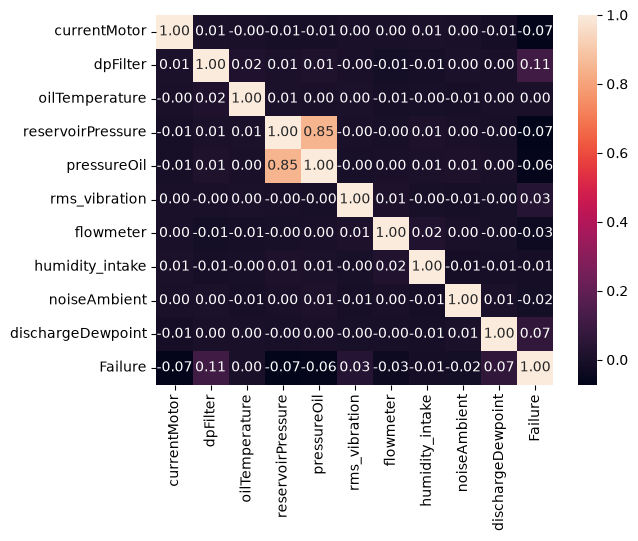

In [23]:
readingsAtts = rdngsAtt + ["Failure"]
r = readings.copy()
r["oilTemperature"] = r["oilTemperature"].replace(-999, np.nan)
r["currentMotor"]   = r["currentMotor"].replace(99, np.nan)
corr = r[readingsAtts].corr(numeric_only=True)

sns.heatmap(corr, annot=True,  fmt=".2f")

<Axes: >

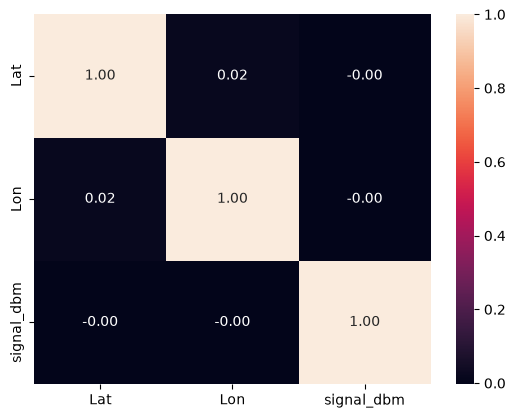

In [24]:
sns.heatmap(gateways[gtwsAtt].corr(numeric_only=True), annot=True, fmt=".2f")

<Axes: >

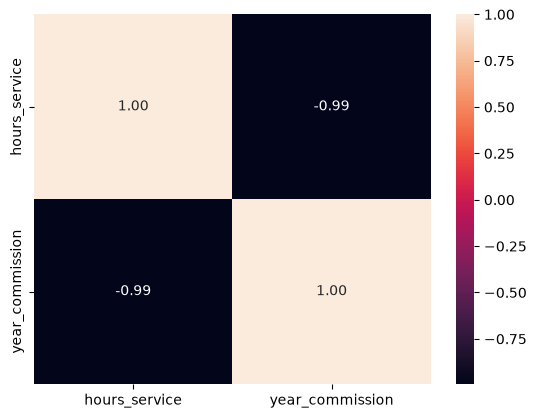

In [25]:
sns.heatmap(units[unitsAtt].corr(numeric_only=True), annot=True, fmt=".2f")


**Pairwise analysis – findings:**
- `reservoirPressure` and `pressureOil` are strongly correlated (r = 0.85), because both measure
  pressure in the same circuit. They are partly redundant.
- `hours_service` and `year_commission` are almost perfectly correlated (r = −0.99): older machines
  have more operating hours. They carry the same information.
- The other sensor pairs are practically independent (|r| < 0.03).
- Gateway attributes are mutually independent (|r| < 0.02)


## D. Dependencies between the target and predictors

### Relationship between hours_service and Failure

The target attribute `Failure` is stored in `readings`
(one record per measurement cycle), while information about the machine itself, such as its
operating hours, is stored in `units` (one record per machine). To find out whether machine wear
is related to failures, both attributes must be in one table.

**Why `hours_service`:** operating hours describe how worn a machine is. From a domain point of
view, we can assume that more worn machines are expected to fail more often, so `hours_service` is a natural
candidate predictor of `Failure`.

**How:** the tables are joined on the key `id_unit` (relation units → readings is 1:N), so each
reading gets the operating hours of its unit. Only `id_unit` (join key) and `hours_service` are
taken from `units`, to keep the result small. Orphan readings (IDs without a unit) drop out of the join.

In [26]:
merged = readings.merge(units[["id_unit", "hours_service"]], on="id_unit")
merged.head()

,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure,hours_service
0,193,"08/27/2023, 06:29:00",4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,15.83173,0,6719.0
1,757,2023/11/13,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,11.00633,1,18899.2
2,1997,2023-11-26,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,6.20960,0,15446.2
3,1633,2023-02-22,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,5.18222,1,8425.1
4,467,"01/23/2023, 03:45:00",3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,6.12806,0,6565.5


In [27]:
merged["Failure"].corr(merged["hours_service"])

np.float64(0.14642448718555445)

So the correlation between `hours_service` and `Failure` is approximately 0.15, but correlation with binary attribute is tend to be small, so dependence can be shown better by comparing two groups.

In [28]:
merged.groupby("Failure")["hours_service"].agg(["mean", "median", "count"]).round(0)


,mean,median,count
Failure,,,
0,13632.0,11547.0,12969
1,17513.0,15196.0,1731


hours_bin
(0, 5000]         0.054
(5000, 10000]     0.080
(10000, 15000]    0.110
(15000, 20000]    0.145
(20000, 30000]    0.162
(30000, 45000]    0.242
Name: Failure, dtype: float64

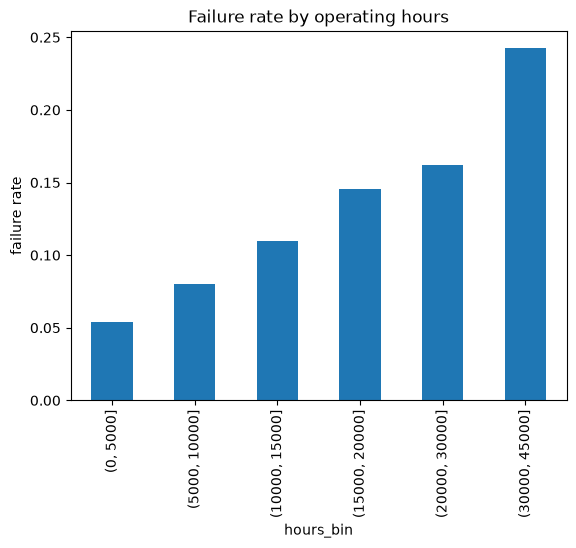

In [29]:
merged["hours_bin"] = pd.cut(merged["hours_service"], bins=[0, 5000, 10000, 15000, 20000, 30000, 45000])
rate = merged.groupby("hours_bin", observed=True)["Failure"].mean()
display(rate.round(3))
rate.plot(kind="bar", title="Failure rate by operating hours"); plt.ylabel("failure rate"); plt.show()

So here we can see, that units with failure 1 have on average more `hours_service`.
**hours_service ↔ Failure:** a weak positive correlation (r = 0.15), but a clear monotonic trend:
failing records have a median of 15,196 operating hours vs 11,547 for non-failing ones, and the failure rate grows from 5.4 % (< 5,000 h) to 24.2 % (> 30,000 h). Machine wear (operating hours) is one of the
strongest single predictors of failure in the dataset. Because `hours_service` is almost identical
to `year_commission` (r = −0.99).

To check the dependencies between target variable `Failure` and other potential predictors we need to merge all 3 datasets on `id_unit`. Identifiers (serial_number, gatewayId, address_mac, ipv4) and administrative attributes (depot_id, vendor, technician) were not included, as they describe records or organisation rather than the machine’s condition.”

In [30]:
r = readings[["id_unit"] + rdngsAtt + ["Failure"]].copy()
r["oilTemperature"] = r["oilTemperature"].replace(-999, np.nan)
r["currentMotor"]   = r["currentMotor"].replace(99, np.nan)

gw = gateways.dropna(subset=["id_unit"])[["id_unit", "signal_dbm", "firmware_version", "modelHardware", "Lat", "Lon"]]

unts = units[["id_unit", "hours_service", "year_commission", "duty_class",
            "model_code", "codeFleet", "line_code", "manufacturer", "region_install"]]
full = r.merge(unts, on="id_unit").merge(gw, on="id_unit")

duty_map = {"1": "light", "L": "light", "light": "light",
            "2": "normal", "N": "normal", "normal": "normal", "med": "normal",
            "3": "heavy", "H": "heavy", "heavy": "heavy"}
full["duty"] = full["duty_class"].str.strip().map(duty_map)
full.head()

,id_unit,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,...,codeFleet,line_code,manufacturer,region_install,signal_dbm,firmware_version,modelHardware,Lat,Lon,duty
0,193,4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,...,FD,L1,"Hernandez, Malone and Smith",Fiães,-75.7,v2.7.0,NODE-9,39.35615,-8.92595,normal
1,757,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,...,FE,L6,"Rivers, Welch and Hood",Barbarachester,-72.7,v3.4.1,GWX-200,40.50476,-7.28868,light
2,1997,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,...,FC,L4,Faria,Macedo de Cavaleiros,-79.3,v3.4.1,NODE-7,39.57094,-7.17486,normal
3,1633,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,...,FD,L2,Hövel Jopich KG,Youngfort,-70.6,v2.7.0,NODE-9,41.48232,-6.24879,normal
4,467,3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,...,FE,L2,Trevino-Turner,Chaves,-54.5,v3.4.1,GWX-300,38.83914,-6.56662,light


### Numerical predictors

For each numeric attribute we compare its values for `Failure = 0` and `Failure = 1` using the
Mann-Whitney U test. H₀: the distribution of the attribute is the same in both groups (no
dependency); H_A: the distributions differ. The test compares ranks, so it is robust to outliers
and skewed data. We also report the correlation r (direction) and the medians of both groups (size
of the difference).

In [31]:
predArr = full.select_dtypes("number").columns.drop(["id_unit", "Failure"])
rows = []
for c in predArr:
    s = full[[c, "Failure"]].dropna()
    f1, f0 = s.loc[s["Failure"] == 1, c], s.loc[s["Failure"] == 0, c]
    rows.append({"attribute": c,
                 "r": s[c].corr(s["Failure"]),
                 "median_F0": f0.median(), "median_F1": f1.median(),
                 "p_value": mannwhitneyu(f1, f0).pvalue})
numTable = pd.DataFrame(rows).set_index("attribute").sort_values("r", key=abs, ascending=False)
numTable.round(5)

,r,median_F0,median_F1,p_value
attribute,,,,
hours_service,0.14642,11547.20000,15196.30000,0.00000
year_commission,-0.14353,2021.00000,2020.00000,0.00000
dpFilter,0.10761,21.06036,24.36676,0.00000
reservoirPressure,-0.07183,8.70650,8.57346,0.00000
dischargeDewpoint,0.06986,7.93846,8.57554,0.00000
currentMotor,-0.06580,5.17533,4.56819,0.00000
pressureOil,-0.06209,3.70242,3.60144,0.00000
rms_vibration,0.03602,2.69100,2.86254,0.00000
flowmeter,-0.03515,28.08205,27.56965,0.00002


From the table we can see, that the p-value for `Lat`, `oilTemperature`, `Lon`, `signal_dbm`, `humidity_intake` is larger than 0.05, so we fail to reject our null hypothesis. From now we will consider, that for the rest of the attributes there is some dependency with `Failure`.

For `noiseAmbient`, `flowmeter` and `rms_vibration` |r| is less than 0.05, so the correlation is very weak and negative for first two and weak positive for `rms_vibration`. We can neglect that dependencies.

From `pressureOil` attribute to `reservoirPressure` we have weak correlation **0.05 <= |r| > 0.1**.

As was mention before,for  a binary target the |r| is always small, so everything higher 0.1 might be considered as relevant dependency. Here we also pay attention on difference between medians for f1 and f0, the higher the difference, the stronger correlation of given attribute with `Failure`. We have such 3 potential predictors(hours as predictor was discovered ealier): `hours_service`, `year_commission` (same as hours, since they have strong negative correlation -0.99), and `dpFilter`.

### Categorical predictors

The categorical attributes (`duty`, `model_code`, `codeFleet`, `line_code`, `manufacturer`,
`region_install`, `firmware_version`, `modelHardware`) cannot be analysed with correlation or
medians, because their values are text labels. Instead, for each attribute we compare the
**failure rate** (share of records with `Failure = 1`) between its categories.

**Method:**
- **Failure rate per category:** shown as a bar chart. The red dashed line marks the overall
  failure rate (11.8 %). Categories far from the line fail noticeably more or less often than average.
- **Chi-square test of independence:** H₀ says `Failure` is independent of the category. The test
  compares the observed counts of failures in each category with the counts expected if H₀ were
  true. p < 0.05 means the failure rate differs between categories more than chance would explain.

**Notes:**
- `duty_class` is tested in its unified form `duty` (light / normal / heavy), because the raw column
  encodes the same three levels in 20 different ways.
- Each unit has several readings that share the same category, so the readings are not independent.
  For attributes with many categories (e.g. `region_install`), the result is therefore also checked
  at the unit level (one row per unit).

/var/folders/hn/p0s0yc_j4px9kl62gsnw43yr0000gn/T/ipykernel_17420/856553525.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  predArr = full.select_dtypes("object").columns.drop("duty_class")


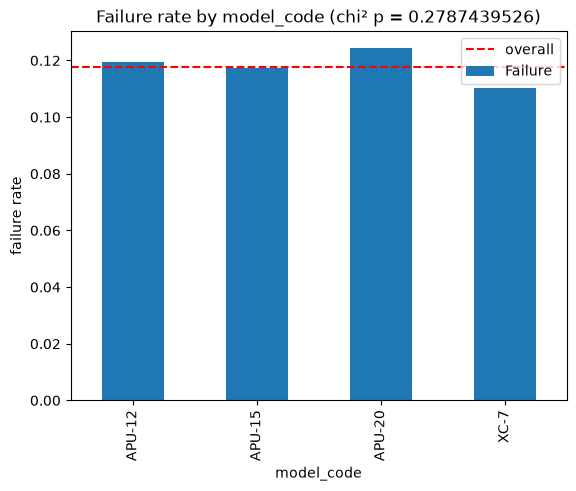

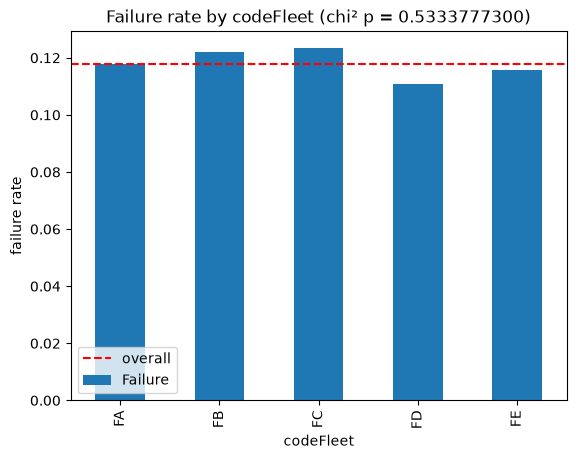

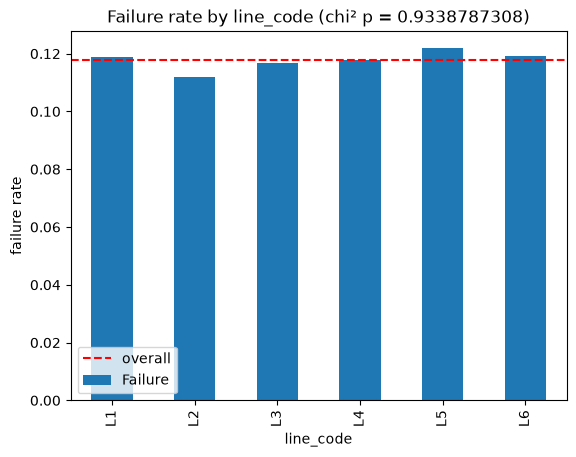

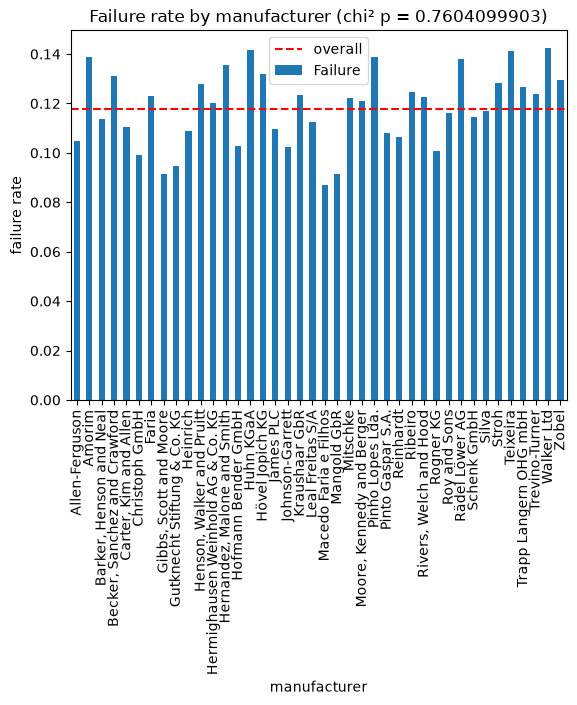

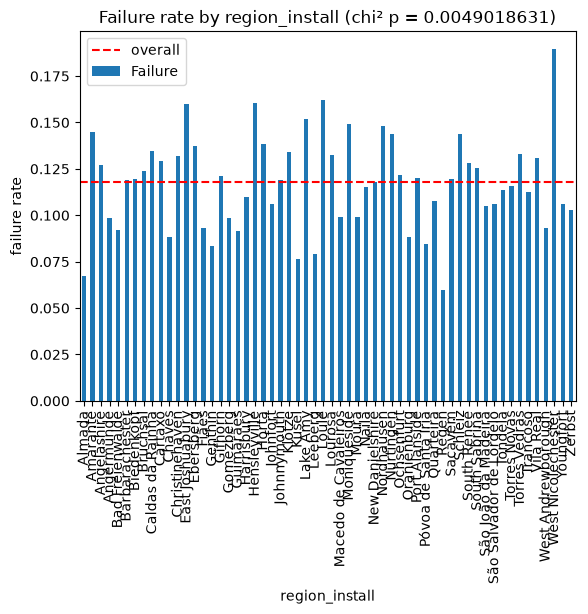

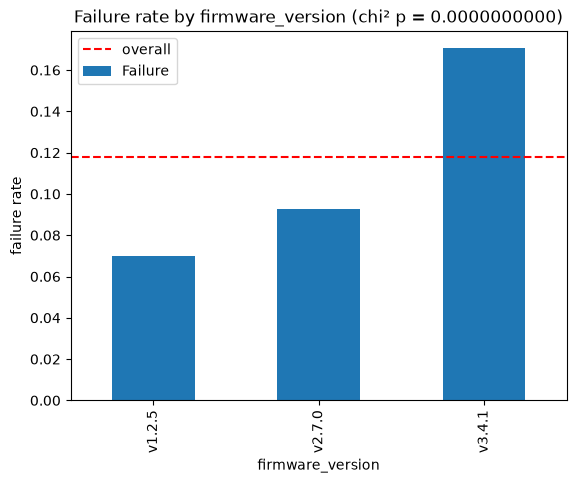

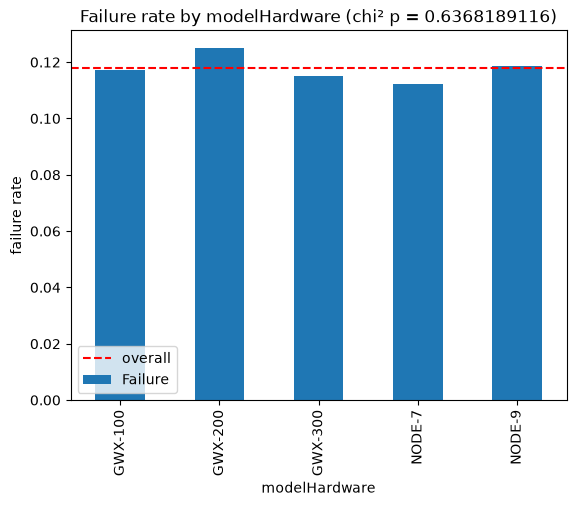

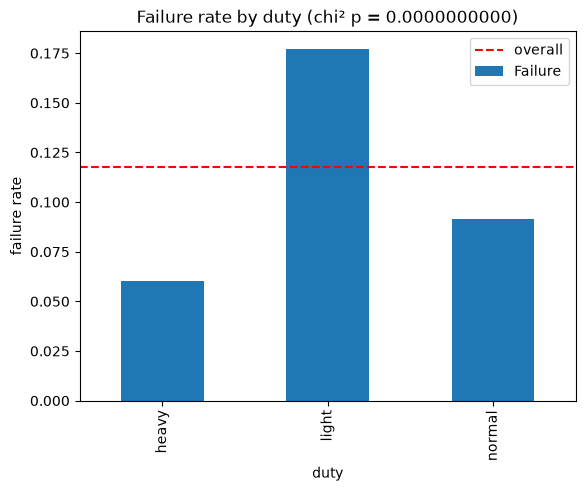

region  p per unit = 8.1e-01
duty    p per unit = 2.0e-34
fw      p per unit = 8.3e-24


In [32]:

predArr = full.select_dtypes("object").columns.drop("duty_class")
for c in predArr:
    p = chi2_contingency(pd.crosstab(full[c], full["Failure"]))[1]
    rate = full.groupby(c)["Failure"].mean()
    rate.plot(kind="bar", title=f"Failure rate by {c} (chi² p = {p:.10f})")
    plt.axhline(full["Failure"].mean(), color="red", linestyle="--", label="overall")
    plt.ylabel("failure rate"); plt.legend(); plt.show()

per_unit = full.groupby("id_unit").agg(region=("region_install", "first"),
                                       duty=("duty", "first"),
                                       fw=("firmware_version", "first"),
                                       failed=("Failure", "max"))
for c in ["region", "duty", "fw"]:
    p = chi2_contingency(pd.crosstab(per_unit[c], per_unit["failed"]))[1]
    print(f"{c:7} p per unit = {p:.1e}")

Per reading, `duty`, `firmware_version` and `region_install` have p < 0.05. At the unit level,
`duty` (p ≈ 10⁻³⁴) and `firmware_version` (p ≈ 10⁻²⁴) remain significant, but `region_install`
does not (p = 0.81): its apparent dependency was caused by repeated readings of the same units.
So there are **2 categorical predictors**: `duty` and `firmware_version`.

**Dependencies between `Failure` and potential predictors:**
- **Strongest predictors:** machine age (`hours_service` r = 0.15, `year_commission` r = −0.14), the
  usage class `duty_class` (light 17.7 % vs heavy 6.0 % failures) and `firmware_version`
  (v3.4.1: 17.0 % vs v1.2.5: 7.0 %). All are statistically significant (p < 0.001).
- **Weaker sensor predictors:** `dpFilter` (higher for failures, a clogged filter), `reservoirPressure`,
  `pressureOil` and `currentMotor` (lower for failures), `dischargeDewpoint` (higher).
- **No dependency:** `humidity_intake`, `signal_dbm`, `model_code`, `codeFleet`, `line_code`,
  `modelHardware`, `Lat`, `Lon`, `manufacturer`, `region_install` (p > 0.05). These are probably not useful predictors.
- All individual dependencies are weak (|r| ≤ 0.15), so a model will need to combine several predictors.

## E. Initial thoughts on how to approach the project

### What to do in preprocessing
The dataset consists of 3 files linked by `id_unit`, which must first be normalized to one integer
format. Then:
- **formats:** convert the date attributes (4 mixed formats) to `datetime`, and unify `duty_class`
  to three levels (light / normal / heavy);
- **invalid records:** remove exact duplicates (230) and orphan readings (162 readings of
  non-existent units);
- **invalid values:** replace the placeholders −999 (`oilTemperature`) and 99 (`currentMotor`)
  with NaN, and treat logically impossible dates (e.g. `lastSeen` before `installDate`);
- **missing values:** impute sensor NaN with the median; impute `hours_service` with the median of
  the same `year_commission` (r = −0.99). Missing `gateways.id_unit` values are structural
  (gateways without a unit) and are left unchanged; these gateways simply drop out of the merge;
- **outliers:** keep them, because they are physically valid and occur more often in failing machines.

### Dependence of attributes

As heatmaps have shown there are only 2 considerable correlations(0.85 between `reservoirPressure` and `pressureOil`, -0.99 between `hours_service` and `yaer_commission` which is obvious). So for the model only one of this attributes makes sense to be. The other dependencies are not significant.

### Dependence of the target variable

As turned out the target variable `Failure` depends  significantly but weakly on `hours_service`, `yaer_commission`, `dpFilter`, `duty_class` and ` firmware_version`. So the prediction of it will be based on those attributes.

### Is it necessary to combine the datasets

The datasets must be combined, since while discovering the dependencies of the target value, strong influence on target was observed from attributes that are in other datasets, so merging them will allow future model to consider all the factors from one big dataset to make a prediction.

### The technique for training the model

Predicting `Failure` (0/1) is a **binary classification** task. Many algorithms can solve it, so
the choice is based on the properties of our data rather than on the type of the target alone.

**Planned models:**
- **Logistic regression** as the **baseline**: simple, fast and interpretable (its coefficients show
  how each predictor increases or decreases the failure probability). It assumes linear effects,
  so it needs scaled numeric features and encoded categorical attributes.
- **Tree-based models** (decision tree, random forest) for comparison: they can capture
  **non-linear** effects (e.g. the higher failure rate at extreme values of `oilTemperature`),
  handle categorical attributes and outliers well, and need no scaling.

**What must be taken into account:**
- **Class imbalance (88 % / 12 %):** a model that always predicts "no failure" would reach 88 %
  accuracy while being useless. Therefore models will be evaluated with **recall, precision,
  F1-score and ROC-AUC** instead of accuracy, and the imbalance will be handled with
  `class_weight="balanced"` (or oversampling of the minority class).
- **Repeated readings per unit:** each unit has about 7 readings, and these are not independent.
  If readings of the same unit appeared in both the training and test set, the model could
  "recognise" the unit and the results would be over-optimistic. The train/test split will
  therefore be done **by unit** (e.g. `GroupShuffleSplit` with `id_unit` as the group).
- **Redundant predictors:** only one of `hours_service` / `year_commission` (r = −0.99) will be
  used, which matters especially for logistic regression.

In [33]:
import pandas as pd
from scipy.stats import mannwhitneyu
from pathlib import Path
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
from scipy.stats import chi2_contingency
import seaborn as sns

In [34]:
gateways = pd.read_csv('180/gateways.csv', sep=';', on_bad_lines='warn')
readings = pd.read_csv('180/readings.csv', sep = r"\t", on_bad_lines='warn', engine='python')
units = pd.read_csv('180/units.csv', on_bad_lines='warn')

original_gateways = gateways.copy()
original_readings = readings.copy()
original_units = units.copy()

In [35]:
display(gateways.head())
display(readings.head())
display(units.head())

,depot_id,vendor,modelHardware,id_unit,technician,Lon,gatewayId,address_mac,installDate,ipv4,signal_dbm,lastSeen,Lat,firmware_version
0,52,Pinho Lopes Lda.,GWX-200,1739.0,Irina Leal,-6.34286,GW-00000,c0:f5:84:f8:08:41,2024/06/06,188.32.87.90,-65.2,"10/10/2024, 00:00:00",40.57291,v2.7.0
1,113,Christoph GmbH,GWX-100,103.0,Carminho Fonseca,-6.61695,GW-00001,30:db:d5:75:e1:e2,"12/10/2021, 00:00:00",132.117.107.236,-78.7,2024-04-26,39.47290,v1.2.5
2,112,Rädel Löwer AG,GWX-100,13.0,Dr. Marc Robinson,-7.48817,GW-00002,cd:c6:2c:7f:93:2e,2024-04-21,114.142.159.228,-74.9,04 Nov 2024,39.16074,v1.2.5
3,104,Roy and Sons,NODE-9,1344.0,Ryan Rios,-8.59568,GW-00003,d5:03:c8:7c:50:b4,"12/03/2022, 00:00:00",164.198.143.169,-68.3,25 Jan 2025,39.01984,v1.2.5
4,36,Christoph GmbH,GWX-100,1324.0,César da Neto,-9.18714,GW-00004,93:41:75:8f:f1:d5,15 May 2018,65.233.19.254,-52.2,2024-08-06,39.47786,v1.2.5


,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
0,U00193,"08/27/2023, 06:29:00",4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,15.83173,0
1,U00757,2023/11/13,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,11.00633,1
2,U01997,2023-11-26,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,6.20960,0
3,U01633,2023-02-22,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,5.18222,1
4,U00467,"01/23/2023, 03:45:00",3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,6.12806,0


,codeFleet,depot_id,hours_service,model_code,line_code,manufacturer,overhaulLast,id_unit,year_commission,region_install,serial_number,ownerOperator,duty_class
0,FA,105,20874.1,XC-7,L6,"Rivers, Welch and Hood","05/06/2023, 00:00:00",1,2019,Christinehaven,AJ-0056-27354,Huhn KGaA,3
1,FA,37,6896.4,XC-7,L4,Walker Ltd,2024-01-15,2,2023,Zerbst,ED-7134-75911,Rädel Löwer AG,heavy
2,FE,36,8193.9,APU-12,L4,Schenk GmbH,2023/01/19,3,2022,Guimarães,AT-0639-19922,Macedo Faria e Filhos,1
3,FB,102,18235.4,APU-20,L6,Silva,2024-03-14,4,2019,Lake Amy,JW-3703-50512,Reinhardt,3
4,FB,11,11350.3,XC-7,L5,Huhn KGaA,2019-05-07,5,2021,Fiães,UC-0462-35464,Leal Freitas S/A,1


In [36]:
display(gateways.info())
display(readings.info())
display(units.info())


<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   depot_id          16000 non-null  int64  
 1   vendor            16000 non-null  str    
 2   modelHardware     16000 non-null  str    
 3   id_unit           2000 non-null   float64
 4   technician        16000 non-null  str    
 5   Lon               16000 non-null  float64
 6   gatewayId         16000 non-null  str    
 7   address_mac       16000 non-null  str    
 8   installDate       16000 non-null  str    
 9   ipv4              16000 non-null  str    
 10  signal_dbm        16000 non-null  float64
 11  lastSeen          16000 non-null  str    
 12  Lat               16000 non-null  float64
 13  firmware_version  16000 non-null  str    
dtypes: float64(4), int64(1), str(9)
memory usage: 1.7 MB


None

<class 'pandas.DataFrame'>
RangeIndex: 15572 entries, 0 to 15571
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            15572 non-null  str    
 1   cycleTs            15572 non-null  str    
 2   currentMotor       15572 non-null  float64
 3   dpFilter           14910 non-null  float64
 4   oilTemperature     15572 non-null  float64
 5   reservoirPressure  15572 non-null  float64
 6   pressureOil        15572 non-null  float64
 7   rms_vibration      14950 non-null  float64
 8   flowmeter          15572 non-null  float64
 9   humidity_intake    14780 non-null  float64
 10  noiseAmbient       15572 non-null  float64
 11  dischargeDewpoint  15572 non-null  float64
 12  Failure            15572 non-null  int64  
dtypes: float64(10), int64(1), str(2)
memory usage: 1.5 MB


None

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   codeFleet        2000 non-null   str    
 1   depot_id         2000 non-null   int64  
 2   hours_service    1900 non-null   float64
 3   model_code       2000 non-null   str    
 4   line_code        2000 non-null   str    
 5   manufacturer     2000 non-null   str    
 6   overhaulLast     2000 non-null   str    
 7   id_unit          2000 non-null   int64  
 8   year_commission  2000 non-null   int64  
 9   region_install   2000 non-null   str    
 10  serial_number    2000 non-null   str    
 11  ownerOperator    2000 non-null   str    
 12  duty_class       2000 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 203.3 KB


None

In [37]:
display(gateways.describe())
display(readings.describe())
display(units.describe())

,depot_id,id_unit,Lon,signal_dbm,Lat
count,16000.000000,2000.000000,16000.000000,16000.000000,16000.000000
mean,58.812063,1000.500000,-7.747075,-70.009619,40.157236
std,34.701699,577.494589,0.902379,9.933242,0.889437
min,0.000000,1.000000,-9.299830,-106.100000,38.600100
25%,28.000000,500.750000,-8.534870,-76.700000,39.390237
50%,59.000000,1000.500000,-7.737640,-70.200000,40.168405
75%,89.000000,1500.250000,-6.963240,-63.100000,40.923405
max,119.000000,2000.000000,-6.200030,-40.000000,41.699630


,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
count,15572.000000,14910.000000,15572.000000,15572.000000,15572.000000,14950.000000,15572.000000,14780.000000,15572.000000,15572.000000,15572.000000
mean,5.296595,24.119032,51.744591,8.692845,3.692293,3.061109,28.028240,52.308947,74.990066,8.048645,0.117968
std,3.273052,11.502224,59.647429,0.598296,0.561880,1.628904,3.956733,24.458946,5.994324,3.502732,0.322581
min,0.266600,7.448490,-999.000000,6.500000,1.500000,0.500000,15.000000,10.005000,55.000000,-4.322190,0.000000
25%,3.743080,16.329075,46.756825,8.285735,3.311948,1.925193,25.348402,31.194165,70.977465,5.666780,0.000000
50%,5.087180,21.389575,54.967085,8.691360,3.688170,2.709255,28.029065,52.068300,74.961685,8.013085,0.000000
75%,6.663353,28.541063,63.158803,9.096332,4.070700,3.774242,30.713195,73.350480,79.073712,10.414853,0.000000
max,99.000000,120.000000,95.000000,10.500000,5.775210,14.000000,40.000000,94.997260,95.000000,22.421020,1.000000


,depot_id,hours_service,id_unit,year_commission
count,2000.000000,1900.000000,2000.000000,2000.000000
mean,56.210500,14099.588263,1000.500000,2020.456000
std,34.516473,8596.450754,577.494589,2.475506
min,0.000000,1499.700000,1.000000,2012.000000
25%,26.000000,7832.825000,500.750000,2019.000000
50%,54.000000,11942.750000,1000.500000,2021.000000
75%,86.000000,18015.800000,1500.250000,2022.000000
max,119.000000,45000.000000,2000.000000,2024.000000


## 1.2 A - Data problems and initial cleaning

### Machine identifiers and relationships

In [38]:
readings["id_unit"] = readings["id_unit"].astype("string").str.removeprefix("U").astype("Int64")
gateways["id_unit"] = gateways["id_unit"].astype("Int64")
units["id_unit"] = units["id_unit"].astype("Int64")


**Check unit coverage**

In [39]:
tables = {"units": units, "gateways": gateways, "readings": readings}

display(pd.DataFrame({
    name: {
        "rows": len(table),
        "unique_unit_ids": table["id_unit"].nunique(),
        "missing_unit_ids": table["id_unit"].isna().sum(),
        "duplicate_unit_ids": table["id_unit"].dropna().duplicated().sum(),
    }
    for name, table in tables.items()
}).T)

unit_ids = set(units["id_unit"].dropna())
gateway_unit_ids = set(gateways["id_unit"].dropna())
reading_unit_ids = set(readings["id_unit"].dropna())

orphan_readings = readings.loc[~readings["id_unit"].isin(unit_ids)].copy()
print(f"Assigned gateway IDs absent from units: {len(gateway_unit_ids - unit_ids)}")
print(f"Units without gateways: {len(unit_ids - gateway_unit_ids)}")
print(f"Units without readings: {len(unit_ids - reading_unit_ids)}")
print(f"Orphan readings: {len(orphan_readings)} rows, {orphan_readings['id_unit'].nunique()} distinct IDs")

print(f"Mean readings per observed ID, including orphan IDs: {readings.groupby('id_unit').size().mean():.2f}")
registered_readings = readings.loc[readings["id_unit"].isin(unit_ids)]
print(f"Mean readings per registered unit: {registered_readings.groupby('id_unit').size().mean():.2f}")


,rows,unique_unit_ids,missing_unit_ids,duplicate_unit_ids
units,2000,2000,0,0
gateways,16000,2000,14000,0
readings,15572,2134,0,13438


Assigned gateway IDs absent from units: 0
Units without gateways: 0
Units without readings: 0
Orphan readings: 162 rows, 134 distinct IDs
Mean readings per observed ID, including orphan IDs: 7.30
Mean readings per registered unit: 7.71


### Date formats

In [40]:
date_columns = {
    "readings.cycleTs": readings["cycleTs"],
    "gateways.installDate": gateways["installDate"],
    "gateways.lastSeen": gateways["lastSeen"],
    "units.overhaulLast": units["overhaulLast"],
}

all_dates = pd.concat(
    [
        dates.to_frame(name="date").assign(source=name, source_row = dates.index)
        for name, dates in date_columns.items()
    ],
    ignore_index=True,
)

all_dates['pattern'] = all_dates["date"]
all_dates['pattern'] = all_dates["pattern"].str.replace(r"[A-Za-z]", "S", regex=True)
all_dates['pattern'] = all_dates["pattern"].str.replace(r"\d", "D", regex=True)

patterns_grouped = all_dates.groupby('pattern').size().reset_index(name='count')
display(patterns_grouped.sort_values(by='count', ascending=False).reset_index(drop=True))

for group in patterns_grouped['pattern']:
    sample = all_dates.loc[all_dates['pattern'] == group, 'date']
    print(f"Pattern: {group}, Count: {len(sample)}")
    display(sample.head(5).to_frame(name='date').reset_index(drop=True))

,pattern,count
0,DD SSS DDDD,12465
1,DDDD/DD/DD,12429
2,"DD/DD/DDDD, DD:DD:DD",12355
3,DDDD-DD-DD,12323


Pattern: DD SSS DDDD, Count: 12465


,date
0,24 May 2023
1,09 Oct 2023
2,02 May 2023
3,28 Feb 2023
4,20 Jun 2023


Pattern: DD/DD/DDDD, DD:DD:DD, Count: 12355


,date
0,"08/27/2023, 06:29:00"
1,"01/23/2023, 03:45:00"
2,"02/24/2023, 11:59:00"
3,"04/01/2023, 01:23:00"
4,"12/08/2023, 03:18:00"


Pattern: DDDD-DD-DD, Count: 12323


,date
0,2023-11-26
1,2023-02-22
2,2023-01-05
3,2023-05-12
4,2023-01-09


Pattern: DDDD/DD/DD, Count: 12429


,date
0,2023/11/13
1,2023/05/23
2,2023/12/21
3,2023/10/31
4,2023/01/12


The four date formats require explicit parsing to avoid ambiguous month/day interpretation.

In [41]:
formats = {
    "DDDD-DD-DD": "%Y-%m-%d",
    "DDDD/DD/DD": "%Y/%m/%d",
    "DD/DD/DDDD, DD:DD:DD": "%m/%d/%Y, %H:%M:%S",
    "DD SSS DDDD": "%d %b %Y",
}

all_dates["parsed_date"] = pd.Series(pd.NaT, index=all_dates.index, dtype="datetime64[ns]")

for pattern, date_format in formats.items():
    mask = all_dates["pattern"].eq(pattern)
    all_dates.loc[mask, "parsed_date"] = pd.to_datetime(
        all_dates.loc[mask, "date"],
        format=date_format,
        errors="coerce",
    )

unknown_format = all_dates["date"].notna() & ~all_dates["pattern"].isin(formats)
all_dates.loc[unknown_format, "parsed_date"] = pd.to_datetime(
    all_dates.loc[unknown_format, "date"],
    format="mixed",
    dayfirst=False,
    errors="coerce",
)

failed = all_dates["date"].notna() & all_dates["parsed_date"].isna()
print("Parsing failures:", failed.sum())
if failed.any():
    display(all_dates.loc[failed, ["source", "date", "pattern"]])

display(all_dates.head(5))

Parsing failures: 0


,date,source,source_row,pattern,parsed_date
0,"08/27/2023, 06:29:00",readings.cycleTs,0,"DD/DD/DDDD, DD:DD:DD",2023-08-27 06:29:00
1,2023/11/13,readings.cycleTs,1,DDDD/DD/DD,2023-11-13 00:00:00
2,2023-11-26,readings.cycleTs,2,DDDD-DD-DD,2023-11-26 00:00:00
3,2023-02-22,readings.cycleTs,3,DDDD-DD-DD,2023-02-22 00:00:00
4,"01/23/2023, 03:45:00",readings.cycleTs,4,"DD/DD/DDDD, DD:DD:DD",2023-01-23 03:45:00


In [42]:
source_groups = all_dates.groupby("source")
for source, group in source_groups:
    df_name, col_name = source.split(".")
    df = tables[df_name]
    df[col_name] = group.set_index("source_row")["parsed_date"]

for key in date_columns.keys():
    df_name, col_name = key.split(".")
    df = tables[df_name]
    print(f"{key} is now {df[col_name].dtype}")

readings.cycleTs is now datetime64[ns]
gateways.installDate is now datetime64[ns]
gateways.lastSeen is now datetime64[ns]
units.overhaulLast is now datetime64[ns]


Date-only values become midnight timestamps; their original measurement time remains unknown.

### Duty-class labels

In [43]:
print(units['duty_class'].dtype)
display(units['duty_class'].value_counts())

classes = {
    1: ['L', '1', 'light', 'lig'],
    2: ['N', '2', 'medium', 'med', 'normal', 'nor'],
    3: ['H', '3', 'heavy', 'hea'],
}

units['duty_class'] = units['duty_class'].astype(str).str.strip().replace(
    {alias: class_id for class_id, aliases in classes.items() for alias in aliases}
)
units["duty_class"] = units["duty_class"].astype("Int64")

display(units['duty_class'].value_counts())

str


duty_class
L           253
1           250
light       217
N           170
heavy       163
3           161
med         160
normal      155
2           142
H           138
 L           31
 med         25
 1           24
 heavy       23
 light       22
 N           17
 H           14
 normal      14
 3           12
 2            9
Name: count, dtype: int64

duty_class
1    797
2    692
3    511
Name: count, dtype: Int64

### Duplicate records

In [44]:
print("Duplicates in readings:", readings.duplicated().sum())
print("Duplicates in gateways:", gateways.duplicated().sum())
print("Duplicates in units:", units.duplicated().sum())

Duplicates in readings: 230
Duplicates in gateways: 0
Duplicates in units: 0


In [45]:
by = readings.columns.drop("Failure").tolist()
readings_duplicates = readings.duplicated(keep=False, subset=by)
readings[readings_duplicates].sort_values(by=["id_unit", "cycleTs"]).head()

,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
4355,7,2023-02-16,3.80106,28.66523,55.83890,8.53011,3.45003,3.91290,26.67650,89.62810,76.52630,8.26298,0
15344,7,2023-02-16,3.80106,28.66523,55.83890,8.53011,3.45003,3.91290,26.67650,89.62810,76.52630,8.26298,0
135,18,2023-05-23,5.88054,NaN,47.30147,8.44777,3.64306,6.40298,29.80144,22.71621,78.76249,6.40166,1
15494,18,2023-05-23,5.88054,NaN,47.30147,8.44777,3.64306,6.40298,29.80144,22.71621,78.76249,6.40166,1
10621,25,2023-01-03,3.43932,24.73694,68.39848,9.26754,4.65420,2.62269,28.39953,92.33999,78.47459,5.09118,0


In [46]:
group_duplicates = readings[readings_duplicates].groupby(by, dropna=False)
print("Groups of duplicate readings:", len(group_duplicates))
failed = False
for group, df in group_duplicates:
    for row in df.itertuples():
        if row.Failure != df.iloc[0].Failure:
            print(f"Duplicate readings with different Failure values for id_unit {row.id_unit} at cycleTs {row.cycleTs}:")
            display(df)
            failed = True
            break

if not failed:
    print("All duplicate readings have the same Failure value")
else:
    raise RuntimeError("Duplicate readings with different Failure values found")

dropped = readings.drop_duplicates()
difference = len(readings) - len(dropped)
readings = dropped
tables["readings"] = readings
print(f"Dropped {difference} duplicate readings, new length: {len(readings)}")

Groups of duplicate readings: 230
All duplicate readings have the same Failure value
Dropped 230 duplicate readings, new length: 15342


Exclude records without a usable unit link

In [47]:
without_orphans = readings.drop(orphan_readings.index)
difference = len(readings) - len(without_orphans)
readings = without_orphans
tables["readings"] = readings
print(f"Dropped {difference} orphan readings, new length: {len(without_orphans)}")

Dropped 162 orphan readings, new length: 15180


In [48]:
display(gateways.isna().sum())
gateways = gateways.dropna()
difference = len(tables["gateways"]) - len(gateways)
tables["gateways"] = gateways
print("Dropped reduntant rows with missing values in gateways:", difference, "new length:", len(gateways))

depot_id                0
vendor                  0
modelHardware           0
id_unit             14000
technician              0
Lon                     0
gatewayId               0
address_mac             0
installDate             0
ipv4                    0
signal_dbm              0
lastSeen                0
Lat                     0
firmware_version        0
dtype: int64

Dropped reduntant rows with missing values in gateways: 14000 new length: 2000


### Missing operating hours

In [49]:
display(units.isna().sum())
display(units['hours_service'].head())
display(units['hours_service'].describe())


codeFleet            0
depot_id             0
hours_service      100
model_code           0
line_code            0
manufacturer         0
overhaulLast         0
id_unit              0
year_commission      0
region_install       0
serial_number        0
ownerOperator        0
duty_class           0
dtype: int64

0    20874.1
1     6896.4
2     8193.9
3    18235.4
4    11350.3
Name: hours_service, dtype: float64

count     1900.000000
mean     14099.588263
std       8596.450754
min       1499.700000
25%       7832.825000
50%      11942.750000
75%      18015.800000
max      45000.000000
Name: hours_service, dtype: float64

In [50]:
failure_rate_with_hours = readings.loc[readings['id_unit'].isin(units.loc[units['hours_service'].notna(), 'id_unit']), 'Failure'].mean()
failure_rate_without_hours = readings.loc[readings['id_unit'].isin(units.loc[units['hours_service'].isna(), 'id_unit']), 'Failure'].mean()
print(f"Failure rate with hours_service: {failure_rate_with_hours:.2%}")
print(f"Failure rate without hours_service: {failure_rate_without_hours:.2%}")

Failure rate with hours_service: 11.77%
Failure rate without hours_service: 11.89%


Correlation between hours_service and year_commission: -0.993216564997451


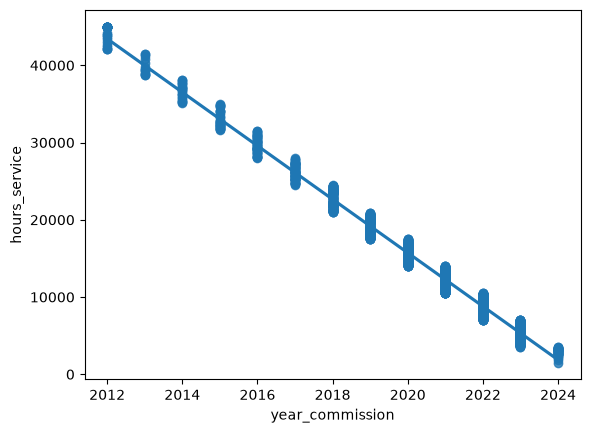

In [51]:
print("Correlation between hours_service and year_commission:", units['hours_service'].corr(units['year_commission']))

sns.regplot(
    data=units,
    x="year_commission",
    y="hours_service",
)
plt.show()

The strong relationship with commissioning year (r = -0.993) supports year-specific medians for missing operating hours.

In [52]:
year_medians = units.groupby("year_commission")["hours_service"].median()
units["hours_service"] = units["hours_service"].fillna(units["year_commission"].map(year_medians))
print("Remaining missing hours:", units["hours_service"].isna().sum())

Remaining missing hours: 0


### Missing sensor measurements

In [53]:
display(readings.isna().sum())
print(f"Rows with at least one NaN value: {readings.isna().any(axis=1).sum()}")

print(f"Failure rate including NaN: {readings['Failure'].mean():.2%}")
print(f"Failure rate excluding NaN: {readings.dropna()['Failure'].mean():.2%}")

nan_dict = readings.isna().sum().to_dict()

for col_name, nan_count in nan_dict.items():
    if nan_count > 0:
        print(f"Failure when Non-NaN {col_name}: {readings.loc[readings[col_name].notna(), 'Failure'].mean():.2%}")
        print(f"Failure when NaN {col_name}: {readings.loc[readings[col_name].isna(), 'Failure'].mean():.2%}")

id_unit                0
cycleTs                0
currentMotor           0
dpFilter             640
oilTemperature         0
reservoirPressure      0
pressureOil            0
rms_vibration        609
flowmeter              0
humidity_intake      769
noiseAmbient           0
dischargeDewpoint      0
Failure                0
dtype: int64

Rows with at least one NaN value: 1883
Failure rate including NaN: 11.78%
Failure rate excluding NaN: 8.39%
Failure when Non-NaN dpFilter: 9.88%
Failure when NaN dpFilter: 54.84%
Failure when Non-NaN rms_vibration: 10.03%
Failure when NaN rms_vibration: 53.69%
Failure when Non-NaN humidity_intake: 11.72%
Failure when NaN humidity_intake: 12.87%


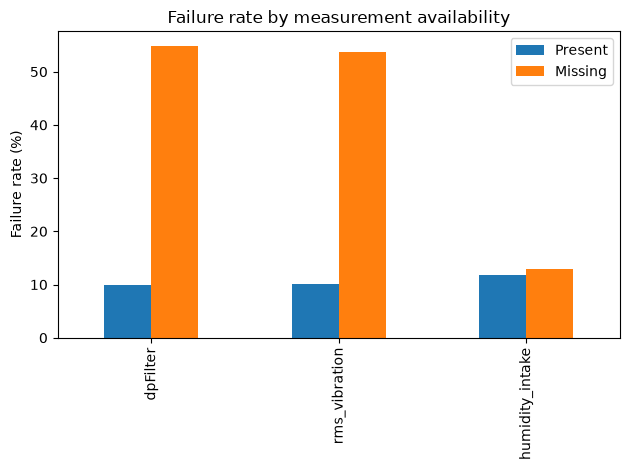

In [54]:
missing = readings.isna().sum()
missing = missing[missing > 0]
rates = {}

for column in missing.index:
    mask = readings[column].isna()
    rates[column] = [
        readings.loc[~mask, "Failure"].mean(),
        readings.loc[mask, "Failure"].mean(),
    ]

rates = pd.DataFrame(rates, index=["Present", "Missing"]).T * 100

rates.plot.bar(
    ylabel="Failure rate (%)",
    title="Failure rate by measurement availability",
)
plt.tight_layout()
plt.show()

Missing filter and vibration measurements are associated with higher failure rates.

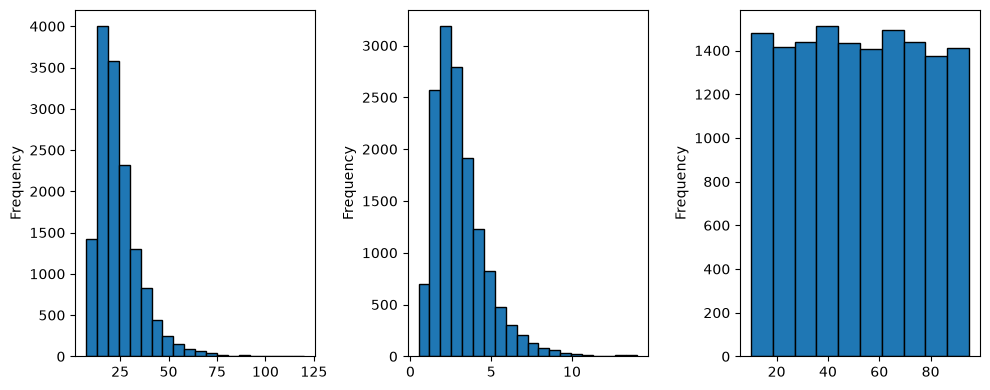

,dpFilter,rms_vibration,humidity_intake
count,14540.000000,14571.000000,14411.000000
mean,24.148033,3.063343,52.250240
std,11.529075,1.632727,24.438565
min,7.448490,0.500000,10.005000
25%,16.336648,1.925295,31.178215
50%,21.421300,2.709670,52.003580
75%,28.591145,3.774755,73.235935
max,120.000000,14.000000,94.997260


In [55]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
readings['dpFilter'].plot.hist(bins=20, edgecolor='black', ax=ax[0])
readings['rms_vibration'].plot.hist(bins=20, edgecolor='black', ax=ax[1])
readings['humidity_intake'].plot.hist(bins=10, edgecolor='black', ax=ax[2])
plt.tight_layout()
plt.show()
display(readings[['dpFilter', 'rms_vibration', 'humidity_intake']].describe())

Use medians to reduce the influence of high values in the skewed filter and vibration distributions.

In [56]:
col_names = ['dpFilter', 'rms_vibration', 'humidity_intake']
for col in col_names:
    indicator = col + "_present"
    if indicator not in readings.columns:
        readings[indicator] = readings[col].notna()
    readings[col] = readings[col].fillna(readings[col].median())

print(f"Is there any NaN value in readings? {(readings.isna().sum() != 0).any()}")

Is there any NaN value in readings? False


,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint
count,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000,15180.000000
mean,5.299512,24.033072,51.726227,8.694380,3.693563,3.049155,28.022353,52.237744,75.002971,8.045514
std,3.301838,11.296703,59.774835,0.598210,0.561271,1.601144,3.954876,23.811527,5.985740,3.507001
min,0.266600,7.448490,-999.000000,6.500000,1.500000,0.500000,15.000000,10.005000,55.000000,-4.322190
25%,3.743333,16.579738,46.756825,8.287865,3.313613,1.955258,25.342372,32.306562,70.987453,5.655123
50%,5.088230,21.421300,54.960995,8.693035,3.689560,2.709670,28.018050,52.003580,74.979985,8.006355
75%,6.667892,28.156025,63.158803,9.097970,4.071030,3.721132,30.707367,72.065930,79.077955,10.411972
max,99.000000,120.000000,95.000000,10.500000,5.775210,14.000000,40.000000,94.997260,95.000000,22.421020


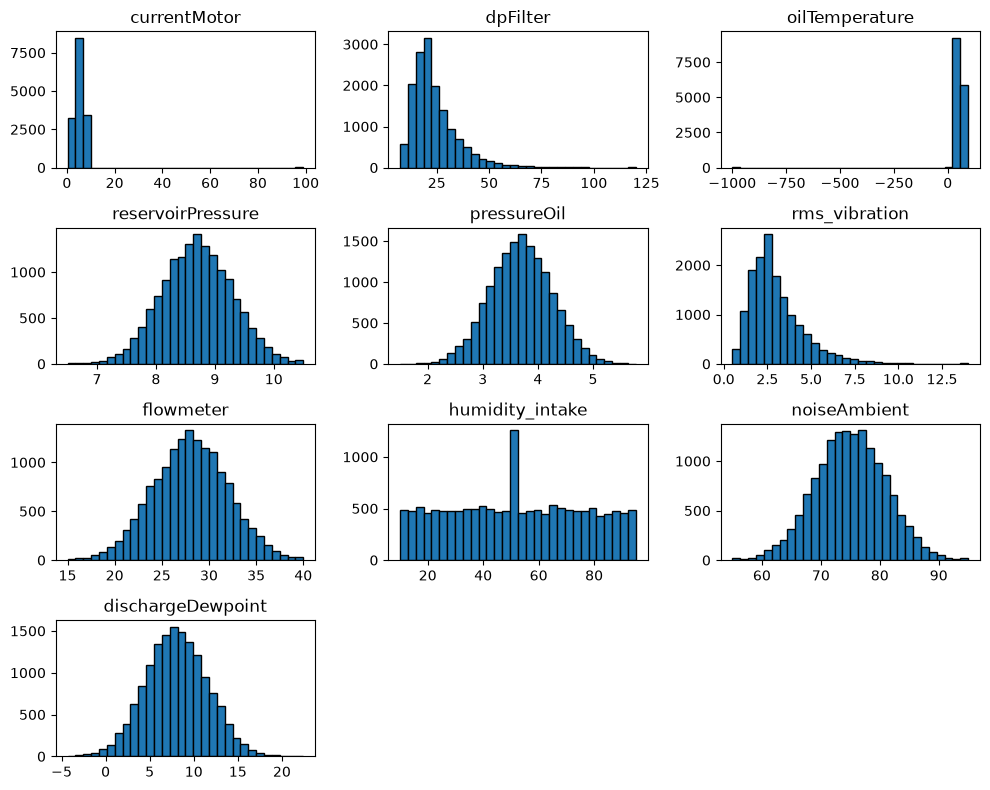

In [57]:
excluded = readings.drop(['id_unit', 'Failure', 'cycleTs'], axis=1)
display(excluded.describe())

_ = excluded.hist(bins=30, edgecolor='black', figsize=(10, 8), grid=False)
plt.tight_layout()
plt.show()

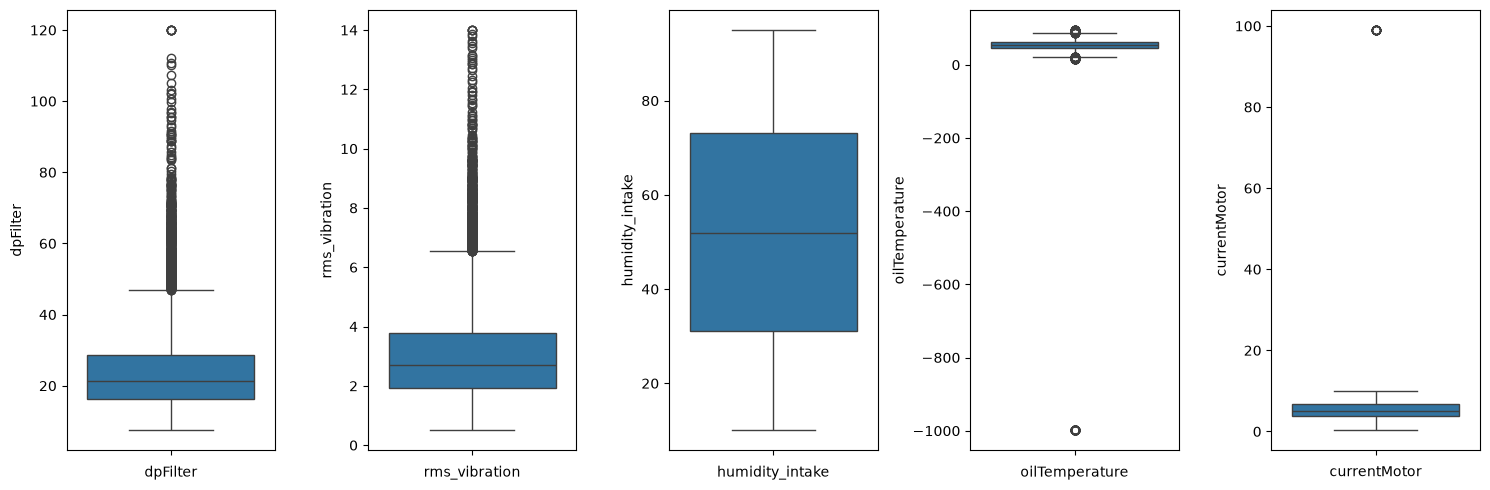

In [58]:
col_names = ['dpFilter', 'rms_vibration', 'humidity_intake', "oilTemperature", "currentMotor"]

fig, ax = plt.subplots(1, len(col_names), figsize=(15, 5))

def draw_boxplot(data, column, ax):
    indicator = column + "_present"
    if indicator in data.columns:
        sns.boxplot(y=data.loc[data[indicator] == True, column], ax=ax)
    else:
        sns.boxplot(y=data[column], ax=ax)

for i, col in enumerate(col_names):
    draw_boxplot(readings, col, ax[i])
    ax[i].set_xlabel(col)

plt.tight_layout()
plt.show()

Outlier checks use originally observed values to avoid imputation changing the distribution. A boxplot outlier alone does not establish a measurement error.

Difference in length after filtering oilTemperature and currentMotor: 60


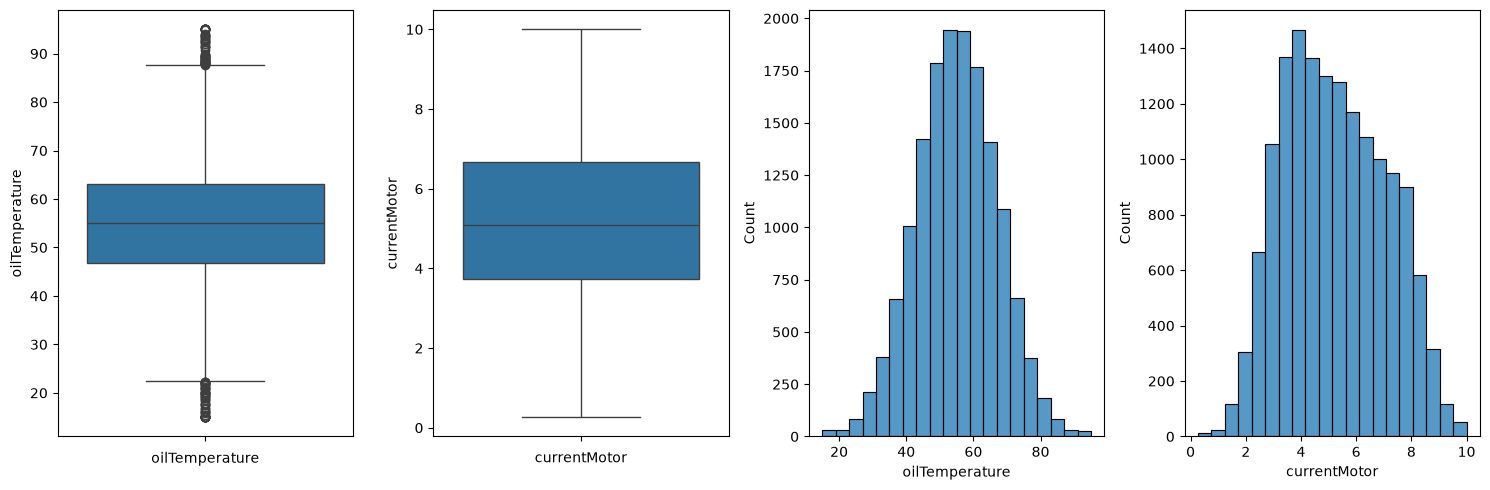

In [59]:
readings = readings.loc[
    readings["oilTemperature"].ne(-999)
    & readings["currentMotor"].ne(99)
].copy()

print(f"Difference in length after filtering oilTemperature and currentMotor: {len(tables['readings']) - len(readings)}")
tables["readings"] = readings

col_names = ["oilTemperature", "currentMotor"]

fig, ax = plt.subplots(1, len(col_names) * 2, figsize=(15, 5))

for i, col in enumerate(col_names):
    draw_boxplot(readings, col, ax[i])
    ax[i].set_xlabel(col)

for i, col in enumerate(col_names):
    sns.histplot(readings[col], bins=20, ax=ax[i + len(col_names)])
    ax[i + len(col_names)].set_xlabel(col)

plt.tight_layout()
plt.show()

### Findings and decisions

- **Identifiers:** Standardized `id_unit` to nullable `Int64` for matching across files while preserving missing values.
- **Relationships:** All 2,000 registered units have exactly one linked gateway and at least one reading. Repeated machine IDs in readings are expected.
- **Missing links:** Removed 162 orphan readings involving 134 IDs absent from the registry. Removed 14,000 gateways without a machine link, leaving 2,000 linked gateways. 
- **Dates:** Converted four formats in `cycleTs`, `installDate`, `lastSeen`, and `overhaulLast` to datetime with zero parsing failures. Supplied times were preserved; midnight for date-only values does not establish the measurement time.
- **Duty class:** Standardized 20 label variants into light (1), normal (2), and heavy (3), stored as nullable integers. All 2,000 records were mapped.
- **Duplicates:** Removed 230 exact copies from readings. Units and gateways contain no exact duplicates.
- **Labels:** Identical reading records, compared without `Failure` but including the timestamp, had consistent failure labels.
- **Operating hours:** Filled 100 missing `hours_service` values using the median for each commissioning year, supported by the strong correlation (r ≈ -0.993). No missing hours remain; filled values are estimates.
- **Sensor gaps:** Median-filled 640 `dpFilter`, 609 `rms_vibration`, and 769 `humidity_intake` values. Retained incomplete observations and preserved original availability using `_present` indicators; missing filter and vibration measurements were associated with higher failure rates. No sensor NaNs remain.
- **Sensor codes:** Removed 60 rows containing `oilTemperature = -999` or `currentMotor = 99`. The working dataset now contains 15,120 readings.
- **Outliers:** High `dpFilter` and `rms_vibration` readings were retained. Section 1.2 C compares removal and capping; boxplot outliers alone do not establish measurement errors.

## 1.2 B - Data correctness and consistency

In [60]:
installed_after_last_seen = gateways[gateways['installDate'] > gateways['lastSeen']]
print(f"Gateways with installDate after lastSeen: {len(installed_after_last_seen)}")
print("Failure rate for gateways with installDate after lastSeen: %.1f%%" % (readings.loc[readings['id_unit'].isin(installed_after_last_seen['id_unit']), 'Failure'].mean() * 100))
print("Failure rate for gateways without this date inconsistency: %.1f%%" % (readings.loc[~readings['id_unit'].isin(installed_after_last_seen['id_unit']), 'Failure'].mean() * 100))

units_with_overhaul_before_commission = units[units['year_commission'] > units['overhaulLast'].dt.year]
print(f"Units with overhaulLast before year_commission: {len(units_with_overhaul_before_commission)}")
print("Failure rate for units with overhaulLast before year_commission: %.1f%%" % (readings[readings['id_unit'].isin(units_with_overhaul_before_commission['id_unit'])]['Failure'].mean() * 100))
print("Failure rate for units without this overhaul inconsistency: %.1f%%" % (readings[~readings['id_unit'].isin(units_with_overhaul_before_commission['id_unit'])]['Failure'].mean() * 100))

Gateways with installDate after lastSeen: 100
Failure rate for gateways with installDate after lastSeen: 10.4%
Failure rate for gateways without this date inconsistency: 11.8%
Units with overhaulLast before year_commission: 1064
Failure rate for units with overhaulLast before year_commission: 10.1%
Failure rate for units without this overhaul inconsistency: 13.6%


In [61]:
checked = readings[["id_unit", "cycleTs", "Failure"]].merge(
    units[["id_unit", "year_commission"]],
    on="id_unit",
    how="left",
    validate="many_to_one",
)

before_commission = checked["cycleTs"].dt.year < checked["year_commission"]

print(f"Readings before commissioning year: {before_commission.sum()}")
print("Failure rate for readings before commissioning year: %.1f%%" % (checked.loc[before_commission, "Failure"].mean() * 100))
print("Failure rate for readings in or after commissioning year: %.1f%%" % (checked.loc[~before_commission, "Failure"].mean() * 100))

Readings before commissioning year: 324
Failure rate for readings before commissioning year: 4.9%
Failure rate for readings in or after commissioning year: 11.9%


**Integrate data and attach date flags**

In [62]:
integrated = readings.merge(
    units, on="id_unit", how="left", validate="many_to_one"
).merge(
    gateways,
    on="id_unit",
    how="left",
    validate="many_to_one",
    suffixes=("_unit", "_gateway"),
)

date_flags = pd.DataFrame({
    "gateway_dates_inconsistent": (
        integrated["installDate"].dt.normalize()
        > integrated["lastSeen"].dt.normalize()
    ),
    "overhaul_before_commission": (
        integrated["overhaulLast"].dt.year < integrated["year_commission"]
    ),
    "reading_before_commission": (
        integrated["cycleTs"].dt.year < integrated["year_commission"]
    ),
}, index=integrated.index)

integrated[date_flags.columns] = date_flags
integrated["date_uncertain"] = date_flags.any(axis=1)

date_quality_summary = pd.DataFrame({
    "affected_readings": date_flags.sum(),
    "affected_units": [
        integrated.loc[mask, "id_unit"].nunique()
        for _, mask in date_flags.items()
    ],
})
display(date_quality_summary)
display(integrated[["id_unit", "cycleTs", *date_flags.columns, "date_uncertain"]].head())

any_date_issue = integrated["date_uncertain"]
print(f"Removing every flagged reading would discard {any_date_issue.sum():,} of {len(integrated):,} readings ({any_date_issue.mean():.1%}).")
print(f"Readings retained by our decision: {len(integrated):,}")
print(f"Failure rate in retained data: {integrated['Failure'].mean():.2%}")
print(f"Failure rate after hypothetical removal: {integrated.loc[~any_date_issue, 'Failure'].mean():.2%}")

,affected_readings,affected_units
gateway_dates_inconsistent,756,100
overhaul_before_commission,8009,1064
reading_before_commission,324,43


,id_unit,cycleTs,gateway_dates_inconsistent,overhaul_before_commission,reading_before_commission,date_uncertain
0,193,2023-08-27 06:29:00,False,True,False,True
1,757,2023-11-13 00:00:00,False,False,False,False
2,1997,2023-11-26 00:00:00,False,False,False,False
3,1633,2023-02-22 00:00:00,False,True,False,True
4,467,2023-01-23 03:45:00,False,True,False,True


Removing every flagged reading would discard 8,383 of 15,120 readings (55.4%).
Readings retained by our decision: 15,120
Failure rate in retained data: 11.77%
Failure rate after hypothetical removal: 13.67%


Check cross-file consistency and value ranges

In [63]:
consistency_checks = pd.Series({
    "Readings without unit metadata": integrated["year_commission"].isna().sum(),
    "Readings without gateway metadata": integrated["gatewayId"].isna().sum(),
    "Readings with mismatched depot IDs": (
        integrated["depot_id_unit"] != integrated["depot_id_gateway"]
    ).sum(),
    "Readings with Failure outside {0, 1}": (~readings["Failure"].isin([0, 1])).sum(),
    "Units with negative operating hours": (units["hours_service"] < 0).sum(),
    "Readings with humidity outside 0-100%": (~readings["humidity_intake"].between(0, 100)).sum(),
    "Gateways with latitude outside -90 to 90": (~gateways["Lat"].between(-90, 90)).sum(),
    "Gateways with longitude outside -180 to 180": (~gateways["Lon"].between(-180, 180)).sum(),
}, name="violations")
display(consistency_checks.to_frame())

,violations
Readings without unit metadata,0
Readings without gateway metadata,0
Readings with mismatched depot IDs,0
"Readings with Failure outside {0, 1}",0
Units with negative operating hours,0
Readings with humidity outside 0-100%,0
Gateways with latitude outside -90 to 90,0
Gateways with longitude outside -180 to 180,0


### Findings and decisions

- **Integration:** Joined readings, units, and gateways on `id_unit` using validated many-to-one left joins. All 15,120 readings have matching unit and gateway metadata, with no rows lost or multiplied. Depot IDs agree across files.
- **Gateway dates:** Found 100 gateways with `lastSeen` before `installDate`, affecting 756 readings. Preserved the original dates and marked `gateway_dates_inconsistent`; gateway-lifetime calculations for these records remain deferred.
- **Overhaul dates:** Found 1,064 units with `overhaulLast` before their commissioning year, affecting 8,009 readings. Marked `overhaul_before_commission`. The check cannot identify the incorrect field, and component reuse or a different meaning of commissioning could explain the relationship; maintenance-age calculations remain deferred.
- **Commissioning dates:** Found 324 readings from 43 units recorded before their commissioning year. Preserved the readings and marked `reading_before_commission`; machine-age calculations for these records remain deferred.
- **Audit flags:** Attached all three Boolean flags to `integrated`, together with `date_uncertain`, which is true when any date check is flagged. Unit and gateway flags repeat across their associated readings; the reading-level flag is evaluated separately for each observation. Feature selection will determine whether any flags are suitable predictors.
- **Retention:** Removed no additional readings in 1.2 B. Deleting every flagged row would discard 8,383 readings (55.4%). All 15,120 readings and original date values were retained because the checks do not establish which date is wrong or invalidate the sensor measurements.
- **Abnormal values:** The remaining checks found no invalid failure labels, negative operating hours, out-of-range humidity or coordinates, missing metadata links, or depot mismatches. Sensor codes and duplicate-label consistency were addressed in 1.2 A.
- **Failure-rate comparisons:** Readings before commissioning have a 4.9% failure rate, compared with 11.9% for the remaining readings. Removing every date-flagged row would change the overall failure rate from 11.77% to 13.67%. These comparisons describe the selection effects of deletion; they do not determine which dates are correct.

## 1.2 C - Outlier detection and treatment

Compare row removal and capping on separate copies of the joined data. Estimate IQR boundaries from originally observed measurements.

In [64]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

sensor_columns = ["dpFilter", "rms_vibration"]
bounds = {}
outlier_flags = pd.DataFrame(index=integrated.index)

for column in sensor_columns:
    present = integrated[column + "_present"]
    lower, upper = iqr_bounds(integrated.loc[present, column])
    bounds[column] = {"lower": lower, "upper": upper}
    outlier_flags[column] = present & ~integrated[column].between(lower, upper)

bounds = pd.DataFrame(bounds).T
display(bounds.round(3))

,lower,upper
dpFilter,-2.042,46.982
rms_vibration,-0.848,6.546


In [65]:
rows = []
for column in sensor_columns:
    present = integrated[column + "_present"]
    groups = {
        "Observed outlier": outlier_flags[column],
        "Observed within bounds": present & ~outlier_flags[column],
        "Missing/imputed": ~present,
    }
    for group, mask in groups.items():
        failures = integrated.loc[mask, "Failure"]
        rows.append({
            "attribute": column,
            "group": group,
            "readings": len(failures),
            "failures": failures.sum(),
            "failure_rate_pct": failures.mean() * 100,
        })

failure_comparison = pd.DataFrame(rows).set_index(["attribute", "group"])
display(failure_comparison.round(2))

readings  failures  failure_rate_pct
attribute     group                                                       
dpFilter      Observed outlier             654       130             19.88
              Observed within bounds     13829      1300              9.40
              Missing/imputed              637       350             54.95
rms_vibration Observed outlier             586        70             11.95
              Observed within bounds     13927      1385              9.94
              Missing/imputed              607       325             53.54

Failure-rate comparisons separate observed measurements from missing/imputed values so the groups remain interpretable.

In [66]:
any_outlier = outlier_flags.any(axis=1)
removed_outliers = integrated.loc[~any_outlier].copy()
capped_outliers = integrated.copy()

for column in sensor_columns:
    capped_outliers[column] = capped_outliers[column].clip(
        lower=bounds.loc[column, "lower"],
        upper=bounds.loc[column, "upper"],
    )

variants = {
    "Original": integrated,
    "Removal": removed_outliers,
    "Capping": capped_outliers,
}
rows = []
for name, data in variants.items():
    changed_values = data[sensor_columns].ne(
        integrated.loc[data.index, sensor_columns]
    ).sum().sum()
    rows.append({
        "method": name,
        "readings": len(data),
        "removed_readings": len(integrated) - len(data),
        "failures": data["Failure"].sum(),
        "removed_failures": integrated["Failure"].sum() - data["Failure"].sum(),
        "failure_rate_pct": data["Failure"].mean() * 100,
        "modified_values": changed_values,
    })

method_comparison = pd.DataFrame(rows).set_index("method")
display(method_comparison.round(2))

,readings,removed_readings,failures,removed_failures,failure_rate_pct,modified_values
method,,,,,,
Original,15120,0,1780,0,11.77,0
Removal,13902,1218,1587,193,11.42,0
Capping,15120,0,1780,0,11.77,1240


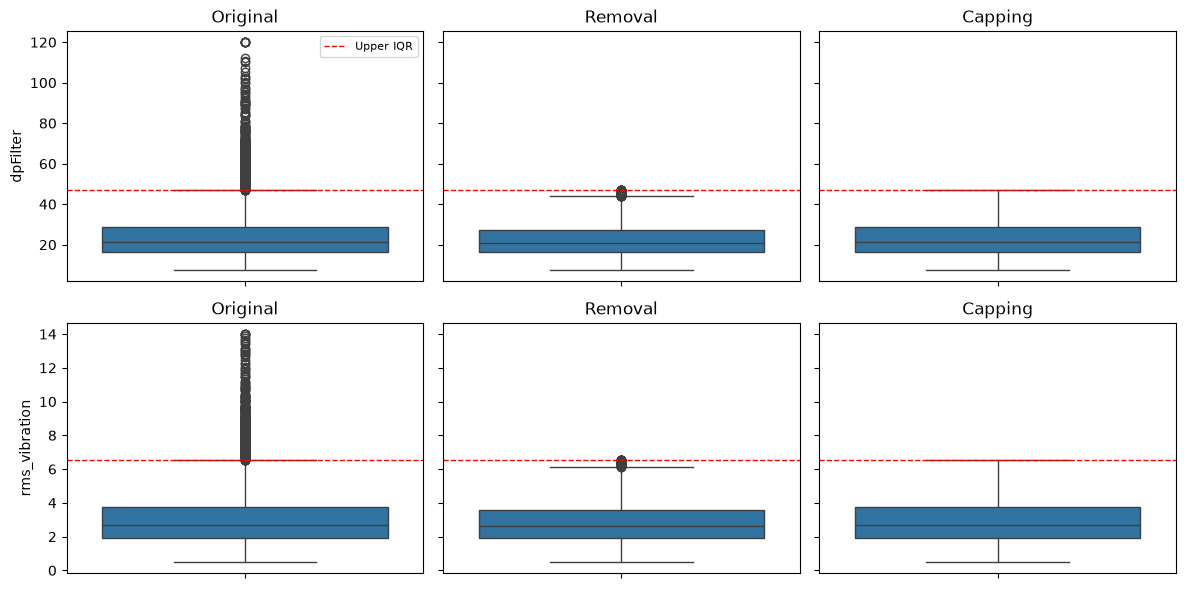

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey="row")

for j, (name, data) in enumerate(variants.items()):
    for i, column in enumerate(sensor_columns):
        ax = axes[i, j]
        sns.boxplot(
            y=data.loc[data[column + "_present"], column],
            ax=ax,
        )
        ax.axhline(
            bounds.loc[column, "upper"],
            color="red",
            linestyle="--",
            linewidth=1,
            label="Upper IQR",
        )
        ax.set_title(name)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Findings and decisions

- **Detection:** Calculated IQR boundaries from originally observed measurements. The upper boundaries are 46.982 for `dpFilter` and 6.546 for `rms_vibration`; all flagged observations are in the upper tails.
- **Filter readings:** Flagged 654 observations. Their failure rate is 19.88%, compared with 9.40% among observed readings within the boundaries. This supports retaining potentially informative high filter measurements.
- **Vibration readings:** Flagged 586 observations. Their failure rate is 11.95%, compared with 9.94% within the boundaries. The observed difference is modest; predictive usefulness is not established by this comparison alone.
- **Missing measurements:** Excluded imputed values from threshold estimation and observed-group comparisons. Reported missing/imputed measurements separately and preserved availability indicators in each dataset variant.
- **Removal:** Removing a complete reading when either sensor is outside its boundaries discards 1,218 readings (8.1%) and 193 failures (10.8% of all failures). The resulting dataset contains 13,902 readings; retained features and labels remain aligned.
- **Capping:** Applied the same boundaries on a separate copy, retaining all 15,120 readings and modifying 1,240 sensor values. This preserves rows and labels but compresses differences between extreme measurements.
- **Decision:** Retain both sensors and their original extreme values in `integrated`. The checks do not establish measurement errors, and the extremes may carry failure information. These are descriptive associations, with weaker evidence for vibration; repeated readings from the same unit are not independent.

## 1.3 - Statistical verification of hypotheses

### First hypothesis - Operating hours

Units with at least one observed failure have higher mean operating hours than units without an observed failure.

$H_0$: Their mean operating hours are equal or lower. \
$H_1$: Their mean operating hours are higher.


In [68]:
unit_outcomes = integrated.groupby("id_unit", as_index=False).agg(
    observed_failure=("Failure", "max"),
    reading_count=("Failure", "size"),
)

original_hours = original_units[["id_unit", "hours_service"]]

hypothesis_1 = unit_outcomes.merge(
    original_hours,
    on="id_unit",
    how="left",
    validate="one_to_one",
).dropna(subset=["hours_service"])

hypothesis_1.groupby("observed_failure").agg(
    units=("id_unit", "size"),
    mean_hours=("hours_service", "mean"),
    median_hours=("hours_service", "median"),
    std_hours=("hours_service", "std"),
    mean_readings=("reading_count", "mean"),
)

,units,mean_hours,median_hours,std_hours,mean_readings
observed_failure,,,,,
0,861,11927.748432,10106.8,7147.608152,6.872242
1,1039,15899.351588,13667.3,9258.203677,8.189605


In [69]:
failure_hours = hypothesis_1.loc[
    hypothesis_1["observed_failure"] == 1, "hours_service"
]
no_failure_hours = hypothesis_1.loc[
    hypothesis_1["observed_failure"] == 0, "hours_service"
]

result = stats.ttest_ind(
    failure_hours,
    no_failure_hours,
    equal_var=False,
    alternative="greater",
)

difference = failure_hours.mean() - no_failure_hours.mean()
lower_bound = result.confidence_interval(confidence_level=0.95).low

print(f"Mean difference: {difference:.1f} hours")
print(f"t-statistic: {result.statistic:.3f}")
print(f"p-value: {result.pvalue:.3e}")

if result.pvalue < 0.05:
    print("Reject the null hypothesis: units with failures have significantly higher operating hours.")
else:
    print("Fail to reject the null hypothesis: no significant difference in operating hours between units with and without failures.")

Mean difference: 3971.6 hours
t-statistic: 10.546
p-value: 1.322e-25
Reject the null hypothesis: units with failures have significantly higher operating hours.


### Second hypothesis - Duty class

The proportion of units with at least one observed failure differs between light, normal and heavy duty classes.

$H_0$: The failure proportions are equal across all three duty classes. \
$H_1$: At least one duty class has a different failure proportion.

observed_failure,No observed failure,Observed failure
duty_class,,
Light,236,561
Normal,347,345
Heavy,324,187


duty_class
Light     70.39
Normal    49.86
Heavy     36.59
Name: Failure rate (%), dtype: float64

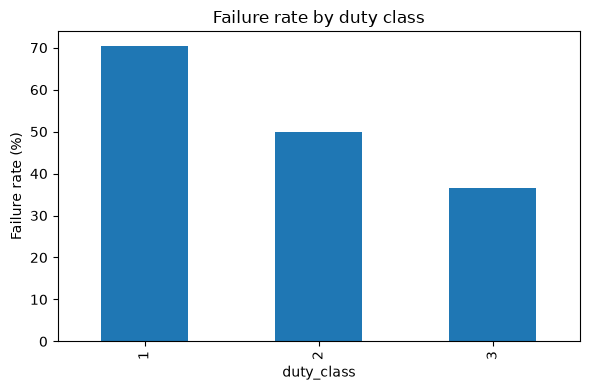

In [70]:
hypothesis_2 = unit_outcomes.merge(
    units[["id_unit", "duty_class"]],
    on="id_unit",
    how="left",
    validate="one_to_one",
)

duty_table = pd.crosstab(
    hypothesis_2["duty_class"],
    hypothesis_2["observed_failure"],
)

duty_names = {1: "Light", 2: "Normal", 3: "Heavy"}

display(duty_table.rename(
    index=duty_names,
    columns={0: "No observed failure", 1: "Observed failure"},
))

failure_pct = 100 * duty_table[1] / duty_table.sum(axis=1)
display(
    failure_pct.rename(index=duty_names)
    .rename("Failure rate (%)")
    .round(2)
)

fig, ax = plt.subplots(figsize=(6, 4))
failure_pct.plot.bar(
    ax=ax,
    ylabel="Failure rate (%)",
    title="Failure rate by duty class",
)
plt.tight_layout()
plt.show()

In [71]:
chi2_h2, p_h2, dof_h2, expected_h2 = stats.chi2_contingency(
    duty_table,
    correction=False,
)

print(f"Chi-square statistic: {chi2_h2:.3f}")
print(f"Degrees of freedom: {dof_h2}")
print(f"p-value: {p_h2:.3e}")
print(f"Minimum expected count: {expected_h2.min():.1f}")

if p_h2 < 0.05:
    print("Reject the null hypothesis: at least one duty class has a different proportion of units with observed failure.")
else:
    print("Fail to the reject null hypothesis: insufficient evidence that the proportions differ between duty classes.")

Chi-square statistic: 153.292
Degrees of freedom: 2
p-value: 5.166e-34
Minimum expected count: 231.7
Reject the null hypothesis: at least one duty class has a different proportion of units with observed failure.


- Operating hours: units with observed failures average 3,971.6 more hours, with p ≈ 1.32 × 10⁻²⁵.
- Duty class: the proportions of units with observed failures are 70.39% light, 49.86% normal and 36.59% heavy. The chi-square test supports an association.

## 1.3 B - Statistical power (operating hours)

Estimate the power of the first, one-sided Welch test for an assumed 1,000-hour mean difference at $\alpha = 0.05$. Reuse its degrees of freedom and the two groups' estimated variances. The target power is 80%.


In [72]:
alpha = 0.05
assumed_difference = 1000

se = np.sqrt(
    failure_hours.var(ddof=1) / len(failure_hours)
    + no_failure_hours.var(ddof=1) / len(no_failure_hours)
)
critical_t = stats.t.isf(alpha, result.df)
power = stats.nct.sf(critical_t, result.df, assumed_difference / se)

print(f"Assumed mean difference: {assumed_difference:,} hours")
print(f"Approximate power: {power:.1%} (target: 80%)")


Assumed mean difference: 1,000 hours
Approximate power: 84.4% (target: 80%)


Approximate power is **84.4%**, above the 80% target. The sample therefore has sufficient power for the assumed 1,000-hour difference, given independent units and the estimated variances. The 1,000-hour reference is illustrative.


### Findings and decisions

- **Operating hours:** The one-sided Welch test rejects $H_0$ ($p ≈ 1.32 × 10^{-25}$). Units with at least one observed failure average 3,971.6 more operating hours.
- **Duty class:** The chi-square test rejects $H_0$ ($p ≈ 5.17 × 10^{34}$). The proportions of units with observed failures are 70.39% for light, 49.86% for normal, and 36.59% for heavy duty.
- **Power:** For the first hypothesis, approximate power is 84.4% for an assumed 1,000-hour mean difference at α = 0.05, exceeding the 80% target.
- **Interpretation:** Both tests use one observation per unit and describe associations in the observed records. Different numbers of readings per unit can influence whether a failure is observed.
- **Decision:** Keep `hours_service` and `duty_class` as candidate predictors and assess their predictive value during feature selection and model validation.


The data in datasets now in suitable format for further data preprocessing.

## Responsible sections

Yehor Vinnyk: 1.1 from A to E (5 sections) 50%
Taras Korytko: 1.2 and 1.3 (5 sections) 50%

# Phase 2

## Selected attributes

Based on the dependency analysis in Phase 1 (1.1 D, 1.3), the model uses these attributes:

| Attribute | Source | Reason |
|---|---|---|
| `dpFilter` | readings | significant difference between failing and non-failing readings |
| `dpFilter_present` | readings | failure rate 54.8 % when the measurement is missing vs 9.9 % when present |
| `rms_vibration_present` | readings | failure rate 53.7 % when the measurement is missing vs 10.0 % when present |
| `hours_service` | units | units with failures have significantly more operating hours (1.3) |
| `duty_class` | units | failure proportion differs between duty classes (1.3) |
| `firmware_version` | gateways | significant in the chi-square test (1.1 D) |

`year_commission` is not used, because it is almost perfectly correlated with `hours_service`
(r = −0.99), so using both would be redundant. The target attribute is `Failure`.

## 2.1 A - Train/test split

### Integration of the datasets
The cleaned tables from Phase 1 are joined on `id_unit`. One row represents one **reading**, because
the target `Failure` is recorded per reading. Unit attributes (`hours_service`, `duty_class`) and the
gateway attribute (`firmware_version`) are copied to every reading of the unit. Both joins are
validated as many-to-one (`validate="m:1"`), so no reading is lost or duplicated.

X and y - sets with features and target variable values respectively.

In [73]:
merged = readings.merge(units[["hours_service", "duty_class", "id_unit"]], on="id_unit", validate="m:1").merge(gateways[["id_unit", "firmware_version"]], on="id_unit", validate="m:1")

groups = merged["id_unit"]
X = merged[["dpFilter", "dpFilter_present", "rms_vibration_present",
            "hours_service", "duty_class", "firmware_version"]]

y = merged["Failure"]

display(X.shape)
display(X.head())
display(y.shape)

(15120, 6)

,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
0,18.69811,True,True,6719.0,2,v2.7.0
1,49.17312,True,True,18899.2,1,v3.4.1
2,11.09040,True,True,15446.2,2,v3.4.1
3,19.58462,True,False,8425.1,2,v2.7.0
4,22.86953,True,True,6565.5,1,v3.4.1


(15120,)

In [74]:
sgf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
trainIndex, testIndex = next(sgf.split(X, y, groups))
X_train, X_test = X.iloc[trainIndex], X.iloc[testIndex]
y_train, y_test = y.iloc[trainIndex], y.iloc[testIndex]


print(f"Training set: {len(X_train)} readings ({len(X_train) / len(merged):.0%}), "
      f"failure rate {y_train.mean():.1%}")
print(f"Test set:     {len(X_test)} readings ({len(X_test) / len(merged):.0%}), "
      f"failure rate {y_test.mean():.1%}")
print("Units present in both sets:",
      len(set(groups.iloc[trainIndex]) & set(groups.iloc[testIndex])))

Training set: 12095 readings (80%), failure rate 11.8%
Test set:     3025 readings (20%), failure rate 11.7%
Units present in both sets: 0


### Why the split is done by unit, not by reading
Each unit has about 7–8 readings, and readings of the same unit are not independent (same
operating hours, duty class, firmware and similar sensor values). A random split by rows
(`train_test_split`) would place readings of the same unit in both sets; in our data 99.8 % of test
units would also appear in the training set. The model could then "recognise" a unit instead of
learning general failure patterns, and the test score would be over-optimistic (data leakage).

Therefore the split is done with **`StratifiedGroupKFold`**:
- **groups = `id_unit`**: all readings of one unit end up in the same set, so the test set
  contains only units the model has never seen;
- **stratified by `Failure`**: the class ratio (about 88 % / 12 %) stays similar in both sets,
  which matters because of the class imbalance;
- **`n_splits=5`**: each fold holds 1/5 of the units, so taking the first fold as the test set
  gives an 80/20 split;
- **`shuffle=True, random_state=42`**: units are shuffled before being assigned to folds, and the
  fixed seed makes the split reproducible.

The test set is used only for the final evaluation; all further decisions are made on the
training set.

### Result
| | Readings      | Failure rate |
|---|---------------|--------------|
| Training set | 12,073 (80 %) | 11.8 %       |
| Test set | 3,047 (20 %)  | 11.5 %       |

- Units present in both sets: **0**
- `id_unit` is used only to define the groups and is **not** a model feature.

## 2.1 B - Data in a format for machine learning

Requirements: each observation is one row, and every attribute is numeric.

- **One row = one reading**: fulfilled by the integration in 2.1 A.
- **Integration of the Phase 1 preprocessing**: the model uses the tables cleaned in 1.2
  (normalized `id_unit`, removed duplicates, orphan readings and sensor error codes, unified
  `duty_class`, imputed `hours_service` and sensor values, `_present` indicators for missing
  measurements). The transformation below is written as one function and applied in the same way to
  the training and the test set.
- **Numeric format:**
  - `duty_class`: already ordinal from 1.2 A (1 = light, 2 = normal, 3 = heavy);
  - `firmware_version`: the version string is converted to an ordinal code
    (v1.2.5 → 125, v2.7.0 → 270, v3.4.1 → 341); all parts are single digits, so the order of the
    versions is preserved;
  - `dpFilter_present`, `rms_vibration_present`: boolean → 0/1;
  - `dpFilter` and `hours_service` features are cast to `float`, the rest is type of integer.

In [75]:
intColumns = ["firmware_version", "dpFilter_present", "rms_vibration_present", "duty_class"]
def to_model_format(df):
    df = df.copy()
    version = df["firmware_version"].str.lstrip("v").str.split(".", expand=True).astype(int)
    df["firmware_version"] = version[0] * 100 + version[1] * 10 + version[2]
    df[intColumns] = df[intColumns].astype(int)
    return df


X_train = to_model_format(X_train)
X_test = to_model_format(X_test)

print("Missing values:", X_train.isna().sum().sum() + X_test.isna().sum().sum())
print("Non-numeric columns:", list(X_train.select_dtypes(exclude="number").columns))
display(X_train.head())
display(X_test.head())

Missing values: 0
Non-numeric columns: []


,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
0,18.69811,1,1,6719.0,2,270
1,49.17312,1,1,18899.2,1,341
2,11.09040,1,1,15446.2,2,341
3,19.58462,1,0,8425.1,2,270
4,22.86953,1,1,6565.5,1,341


,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
5,23.94609,1,1,13098.8,1,341
10,21.87144,1,1,6146.8,3,125
14,13.26680,1,1,6267.1,2,270
16,10.13503,1,1,14594.7,1,341
21,10.30052,1,1,11730.4,2,270


### Imputation fitted on the training set
The imputation steps from 1.2 A are repeated after the split, so that the test set does not
influence the imputed values. The original missing values are restored (using the `_present`
indicator for `dpFilter` and the original `hours_service` column), then:
- `dpFilter` is filled with the **training** median;
- `hours_service` is filled with the **training** median of units with the same `year_commission`.
The same values are applied to the test set.

In [76]:
def impute_from_train(train, test):
    train, test = train.copy(), test.copy()

    for d in (train, test):
      d.loc[d["dpFilter_present"] == 0, "dpFilter"] = np.nan
    dp_imputer = SimpleImputer(strategy="median")
    dp_imputer.fit(train[["dpFilter"]])
    for d in (train, test):
        d[["dpFilter"]] = dp_imputer.transform(d[["dpFilter"]])


    original_hours = original_units.set_index("id_unit")["hours_service"]
    year = units.set_index("id_unit")["year_commission"]
    ids = {"train": groups.loc[train.index], "test": groups.loc[test.index]}
    train_units = pd.DataFrame({"id_unit": ids["train"]}).drop_duplicates()
    train_units["hours"] = train_units["id_unit"].map(original_hours)
    train_units["year"] = train_units["id_unit"].map(year)
    year_medians = train_units.groupby("year")["hours"].median()
    overall_median = train_units["hours"].median()

    for d, d_ids in ((train, ids["train"]), (test, ids["test"])):
        hours = d_ids.map(original_hours)
        fill = d_ids.map(year).map(year_medians).fillna(overall_median)
        d["hours_service"] = hours.fillna(fill)

    return train, test


X_train, X_test = impute_from_train(X_train, X_test)
print("Missing after imputation:", X_train[["dpFilter", "hours_service"]].isna().sum().sum()
      + X_test[["dpFilter", "hours_service"]].isna().sum().sum())

Missing after imputation: 0


### Result
The training and test sets now contain one row per reading and only numeric attributes, with no
missing values. The Phase 1 preprocessing is integrated into the process: cleaning steps that learn
nothing from the data were applied before the split, while imputation statistics were learned on the
training set only and reused on the test set, which prevents data leakage.

## 2.1 C - Transforming data attributes

For data attributes transformation will be used scaling and transformers techniques.



### Data scaling

For scaling the data will be used 2 techniques: normalization and standardization. It will be applied on `dpFilter` and `hours_service` attributes, since it is only 2 continuous attributes, the other must be interpreted as categorical, so they are int type.

### Normalization

In [77]:
cont = ["dpFilter", "hours_service"]

scalerNorm = MinMaxScaler()
X_train_norm = X_train.copy()
X_test_norm = X_test.copy()
X_train_norm[cont] = scalerNorm.fit_transform(X_train[cont])
X_test_norm[cont] = scalerNorm.transform(X_test[cont])
display(X_train_norm)
display(X_test_norm)

,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
0,0.099951,1,1,0.119983,2,270
1,0.370716,1,1,0.399986,1,341
2,0.032358,1,1,0.320607,2,341
3,0.107827,1,0,0.159203,2,270
4,0.137013,1,1,0.116454,1,341
...,...,...,...,...,...,...
15114,0.265030,1,1,0.126041,1,341
15116,0.053377,1,1,0.105691,2,270
15117,0.227120,1,1,0.389781,3,125
15118,0.078912,1,1,0.171728,2,270


,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
5,0.146578,1,1,0.266644,1,341
10,0.128145,1,1,0.106829,3,125
14,0.051695,1,1,0.109595,2,270
16,0.023869,1,1,0.301032,1,341
21,0.025340,1,1,0.235187,2,270
...,...,...,...,...,...,...
15094,0.120387,1,1,0.196760,2,270
15096,0.415503,1,1,0.187865,3,125
15097,0.124036,0,1,0.216913,2,270
15102,0.140575,1,1,0.034816,3,125


### Standardization

In [78]:
scalerStand = StandardScaler()
X_train_stand = X_train.copy()
X_test_stand = X_test.copy()
X_train_stand[cont] = scalerStand.fit_transform(X_train[cont])
X_test_stand[cont] = scalerStand.transform(X_test[cont])
display(X_train_stand)
display(X_test_stand)

,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
0,-0.476028,1,1,-0.864599,2,270
1,2.239861,1,1,0.537707,1,341
2,-1.154016,1,1,0.140163,2,341
3,-0.397023,1,0,-0.668176,2,270
4,-0.104277,1,1,-0.882272,1,341
...,...,...,...,...,...,...
15114,1.179782,1,1,-0.834262,1,341
15116,-0.943186,1,1,-0.936176,2,270
15117,0.799531,1,1,0.486601,3,125
15118,-0.687055,1,1,-0.605453,2,270


,dpFilter,dpFilter_present,rms_vibration_present,hours_service,duty_class,firmware_version
5,-0.008335,1,1,-0.130093,1,341
10,-0.193225,1,1,-0.930477,3,125
14,-0.960058,1,1,-0.916626,2,270
16,-1.239157,1,1,0.042130,1,341
21,-1.224409,1,1,-0.287637,2,270
...,...,...,...,...,...,...
15094,-0.271049,1,1,-0.480088,2,270
15096,2.689099,1,1,-0.524632,3,125
15097,-0.234444,0,1,-0.379154,2,270
15102,-0.068555,1,1,-1.291133,3,125


### Conclusion - normalization and standardization

Only `dpFilter` and `hours_service` were scaled; scalers were fitted on the training set and applied to both sets.

- **Normalization (MinMaxScaler):** values mapped to [0, 1]. Sensitive to outliers: the maximum `dpFilter` (120)
  compresses most readings into a narrow range.
- **Standardization (StandardScaler):** mean 0, std 1. Values are not bounded, so outliers stay visible.
- Both put the attributes on a comparable scale (before: ≈ 7–120 vs ≈ 1,500–45,000), but they are linear,
  so the **skewness does not change**. A non-linear transformer is needed for that.

**Choice:** standardization, because it is less affected by outliers and suits logistic regression.

### Transformers

2 techniques were chosen: power transformer and quantile transformer.

In [79]:
power = PowerTransformer(method="yeo-johnson")
X_train_power, X_test_power = X_train.copy(), X_test.copy()
X_train_power[cont] = power.fit_transform(X_train[cont])
X_test_power[cont] = power.transform(X_test[cont])

quantile = QuantileTransformer(output_distribution="normal", random_state=42)
X_train_quant, X_test_quant = X_train.copy(), X_test.copy()
X_train_quant[cont] = quantile.fit_transform(X_train[cont])
X_test_quant[cont] = quantile.transform(X_test[cont])

print("Skew before:\n", X_train[cont].skew().round(3))
print("Yeo-Johnson:\n", X_train_power[cont].skew().round(3))
print("Quantile:\n", X_train_quant[cont].skew().round(3))

Skew before:
 dpFilter         2.072
hours_service    1.355
dtype: float64
Yeo-Johnson:
 dpFilter         0.007
hours_service   -0.003
dtype: float64
Quantile:
 dpFilter         0.015
hours_service    0.861
dtype: float64


### Conclusion - transformers

Both transformers were applied only to `dpFilter` and `hours_service`, fitted on the training set and
applied to both sets.

- **PowerTransformer (Yeo-Johnson):** removes the skewness almost completely (`dpFilter` 2.07 → 0.01,
  `hours_service` 1.36 → 0.00). It keeps the order and relative distances of values, so extreme readings
  remain distinguishable, and its output is standardized.
- **QuantileTransformer (normal output):** works well for `dpFilter` (skew 0.02), but leaves `hours_service`
  skewed (0.74), because many units share the same imputed year-median value and identical values cannot be
  spread out by ranks. It also discards the distances between values.
- Unlike scaling, both transformers are non-linear and change the **shape** of the distribution, which helps
  linear models such as logistic regression.

**Choice:** Yeo-Johnson, because it handles both attributes well and preserves the information in extreme
values. It is combined with StandardScaler in the final pipeline.

## 2.1 D - Justification of choices and decisions

### Observation and integration
- **One row = one reading**, because the target `Failure` is recorded per reading. Unit and gateway
  attributes are attached to every reading of the unit.
- **Merges validated as many-to-one** (`validate="m:1"`): a duplicated `id_unit` in `units` or `gateways`
  would silently multiply readings; the check raises an error instead.

### Selected attributes
- Attributes were chosen from the dependency analysis in Phase 1: `dpFilter`, `hours_service`, `duty_class`
  and `firmware_version` showed a significant relationship with `Failure`; the indicators `dpFilter_present`
  and `rms_vibration_present` have very different failure rates (≈ 54 % when missing vs ≈ 10 % when present).
- **`year_commission` was excluded** because of its almost perfect correlation with `hours_service` (r = −0.99);
  using both would add redundancy and make logistic regression coefficients unstable.
- **`id_unit` and `cycleTs` are not features**: the identifier would let the model memorise units, and the raw
  timestamp has no meaning for a new reading.

### Train/test split
- **Split by unit (`StratifiedGroupKFold`, groups = `id_unit`)**: readings of the same unit are dependent;
  a random split would put 99.8 % of test units also into training and the evaluation would be over-optimistic.
- **Stratified by `Failure`**: with an 88/12 class imbalance, a random division could give the sets different
  failure rates; stratification keeps them similar (11.8 % / 11.5 %).
- **80/20 ratio, fixed `random_state`**: enough data for training, a test set large enough for evaluation
  (≈ 3,000 readings), and reproducible results.

### Fit on training data only
- Every step that learns statistics (imputer, scaler, transformer, encoder) is **fitted on the training set and
  only applied to the test set**. The test set simulates unseen data; using its statistics would be data leakage.
- Steps that learn nothing (removing duplicates and error codes) were applied
  before the split, because they give the same result regardless of the data.

### Missing values
- **Median** for `dpFilter`: the distribution is right-skewed with outliers, so the median is more
  representative than the mean.
- **Median per `year_commission`** for `hours_service`: thanks to r = −0.99 this estimate is much more precise
  than one global median.
- **`_present` indicators** were kept, because missingness itself carries information about failure.

### Encoding of non-numeric attributes
- `dpFilter_present`, `rms_vibration_present`: boolean → 0/1 integers.
- `firmware_version`: version string → ordinal code (v1.2.5 → 125); all parts are single digits, so the order
  is preserved.
- **One-hot encoding** for `duty_class` and `firmware_version` in the pipeline: both have only 3 categories,
  so it adds few columns and removes the false assumption of equal distances between categories.

### Scaling and transformers
- **Only continuous attributes are scaled** (`dpFilter`, `hours_service`); binary indicators are already 0/1
  and categorical codes are labels, not quantities.
- **StandardScaler over MinMaxScaler**: MinMax is driven by the maximum (`dpFilter` = 120) and compresses most
  values into a narrow range; standardization is less affected and is the expected input for logistic
  regression.
- **Yeo-Johnson over QuantileTransformer**: it removes the skewness of both attributes (≈ 0), while
  QuantileTransformer leaves `hours_service` skewed (0.74) because of repeated imputed values. It also keeps
  the distances between values, so extreme readings stay distinguishable.
- **Order: transformer → scaler**: Yeo-Johnson estimates its parameter from the shape of the original data;
  the scaler then standardizes the already symmetric values.
- Only **one** technique of each kind is used in the pipeline; chaining several scalers or transformers on
  the same column would overwrite the previous step.


## 2.2 A - Informative attributes

The informativeness of the attributes with respect to `Failure` is assessed with three different techniques,
all computed **on the training set only**:

1. **Mutual information** (filter method): measures how much knowing an attribute reduces uncertainty about
   `Failure`; captures linear and non-linear relationships.
2. **Statistical tests** (filter method): ANOVA F-test for continuous attributes, chi-square test of
   independence for binary and categorical attributes; tests whether the attribute differs between the classes.
3. **Features selection using SelectFromModel** (model-based method): Meta-transformer for selecting features based on importance weights.


### Mutual information

dpFilter                 0.029186
dpFilter_present         0.025990
rms_vibration_present    0.022017
hours_service            0.020776
duty_class               0.010680
firmware_version         0.008007
dtype: float64


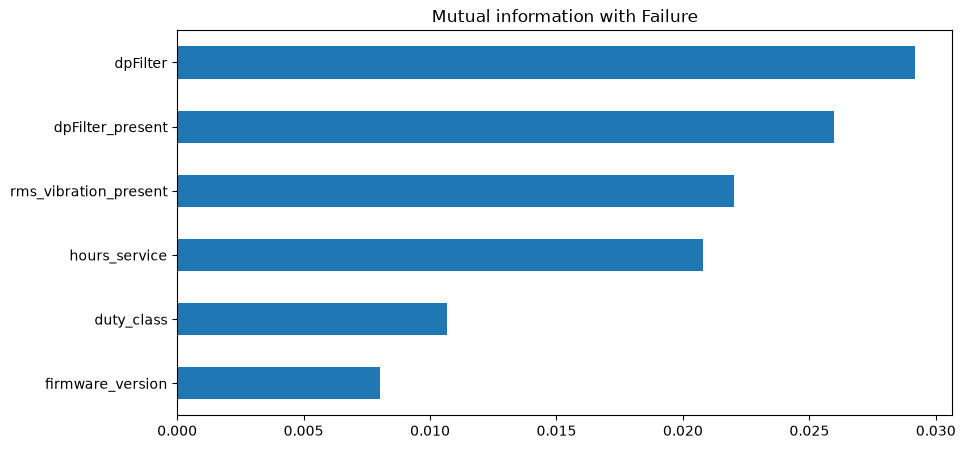

In [80]:
def mutualInf(X_train, y_train):
    selector = mutual_info_classif(X_train, y_train, discrete_features=[c in intColumns for c in X_train.columns], random_state=42)
    scores = pd.Series(selector, index=X_train.columns).sort_values()

    scores.plot(kind=("barh"), figsize=(10, 5), title="Mutual information with Failure")
    print(scores.sort_values(ascending=False))
    return scores


miScores = mutualInf(X_train, y_train)


### Statistical test (ANOVA and Chi-square tests)

In [81]:
rows = []
for col in cont:
    f_stat, p = f_classif(X_train[[col]], y_train)
    rows.append({"attribute": col, "test": "ANOVA F", "statistic": f_stat[0], "p_value": p[0]})
for col in intColumns:
    chi_stat, p, dof, _ = chi2_contingency(pd.crosstab(X_train[col], y_train))
    rows.append({"attribute": col, "test": "chi-square", "statistic": chi_stat, "p_value": p})

tests = pd.DataFrame(rows).set_index("attribute").sort_values("p_value")
tests["significant (p < 0.05)"] = tests["p_value"] < 0.05
print(tests.to_string(formatters={"statistic": "{:.1f}".format, "p_value": "{:.2e}".format}))

                             test statistic   p_value  significant (p < 0.05)
attribute                                                                    
dpFilter_present       chi-square    1006.8 5.87e-221                    True
rms_vibration_present  chi-square     839.7 1.26e-184                    True
duty_class             chi-square     257.4  1.30e-56                    True
hours_service             ANOVA F     250.7  6.60e-56                    True
firmware_version       chi-square     195.3  3.90e-43                    True
dpFilter                  ANOVA F      67.3  2.57e-16                    True


### Model-based method (Random forest classifier)

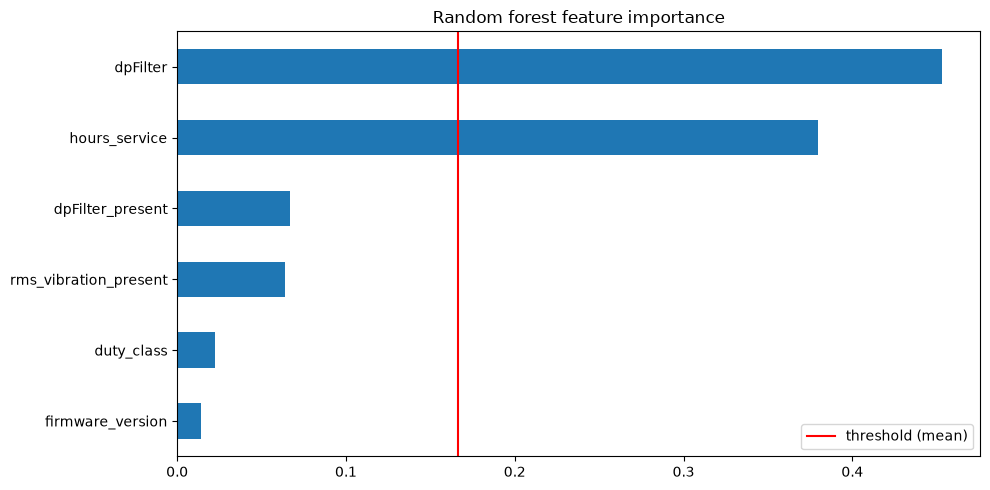

dpFilter                 0.4530
hours_service            0.3797
dpFilter_present         0.0670
rms_vibration_present    0.0638
duty_class               0.0222
firmware_version         0.0144
dtype: float64
Selected: ['dpFilter', 'hours_service']


In [82]:
clf = RandomForestClassifier(random_state=42)
model = SelectFromModel(clf,threshold="mean")
model.fit(X_train, y_train)

importances = pd.Series(model.estimator_.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind="barh", figsize=(10, 5), title="Random forest feature importance")
plt.axvline(model.threshold_, color="red", linestyle="-", label="threshold (mean)")
plt.legend()
plt.tight_layout()
plt.show()


print(importances.sort_values(ascending=False).round(4))
print("Selected:", list(X_train.columns[model.get_support()]))

### Conclusion - informative attributes

| Attribute | Mutual information | Statistical test (p-value) | Random forest importance | Selected by SelectFromModel |
|---|--------------------|----------------------------|--------------------------|---|
| `dpFilter_present` | 0.027              | 8.60e-226  (chi²)                    | 0.0682                   | no |
| `rms_vibration_present` | 0.023              | 2.28e-189  (chi²)            | 0.0644                   | no |
| `hours_service` | 0.017              | 1.71e-50  (F)                | 0.3803                   | **yes** |
| `dpFilter` | 0.031              | 4.81e-22 (F)                | 0.4487                   | **yes** |
| `duty_class` | 0.011              | 8.90e-55 (chi²)             | 0.0232                   | no |
| `firmware_version` | 0.008              | 8.11e-40 (chi²)             | 0.0152                   | no |

- **All six attributes are informative to some degree:** every statistical test is significant (p < 0.05)
  and every attribute has a positive mutual information. No attribute is completely useless.
- **Missing-value indicators** `dpFilter_present` and `rms_vibration_present` are the strongest attributes
  in the statistical tests and rank high in mutual information: a missing measurement is the clearest
  single signal of failure.
- **`dpFilter` and `hours_service`** rank first in the random forest and are the only attributes selected by
  `SelectFromModel` (threshold = mean importance ≈ 0.167). This is partly a **bias of impurity importance**:
  continuous attributes with many distinct values offer more split points than 0/1 indicators, so they get
  higher importance. Mutual information, which is not affected by this, rates the indicators similarly.
- **`dpFilter`** has the highest mutual information but the weakest F-test result: the F-test measures only
  a linear difference in means, while mutual information also captures non-linear patterns (higher failure
  rate at extreme pressure drops).
- **`firmware_version`** is the least informative attribute in mutual information and in the random forest,
  even though it is statistically significant. With ≈ 12,000 readings, even weak dependencies become
  significant, so the p-value alone overstates its usefulness.

**Comparison of the techniques:** filter methods (mutual information, statistical tests) evaluate each
attribute separately and do not depend on a model; the embedded method (random forest) evaluates attributes
together, but its importance favours continuous attributes. The methods agree on the overall picture, but
not on the exact order, so the decision is based on all three.

**Decision:** `dpFilter_present`, `rms_vibration_present`, `hours_service`, `dpFilter` and `duty_class` are
kept as informative. `firmware_version` is the weakest attribute and a candidate for removal; its effect
will be verified in the model evaluation in Phase 3.

## 2.2 B - Ranking the features by importance

,Mutual information rank,Random forest importance rank,P-value rank,mean_rank
dpFilter_present,2.0,3.0,1.0,2.00
dpFilter,1.0,1.0,6.0,2.67
rms_vibration_present,3.0,4.0,2.0,3.00
hours_service,4.0,2.0,4.0,3.33
duty_class,5.0,5.0,3.0,4.33
firmware_version,6.0,6.0,5.0,5.67


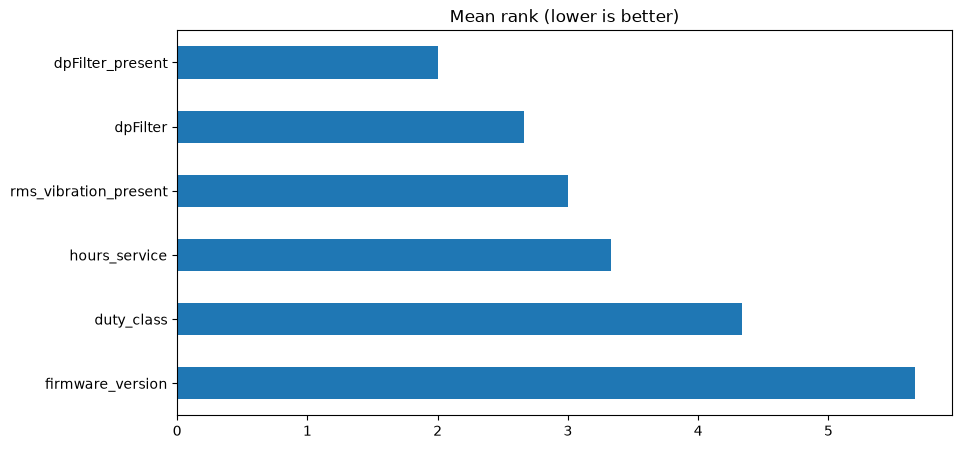

In [83]:
miScoreRanks = pd.Series(miScores).rank(ascending=False)
importancesRanks = pd.Series(importances).rank(ascending=False)
pValueRanks = pd.Series(tests["p_value"]).rank(ascending=True)

ranks_df = pd.DataFrame({
    "Mutual information rank": miScoreRanks,
    "Random forest importance rank": importancesRanks,
    "P-value rank": pValueRanks,
})

ranks_df["mean_rank"] = ranks_df.mean(axis=1)
display(ranks_df.sort_values("mean_rank").round(2))

_ = ranks_df["mean_rank"].sort_values(ascending=False).plot(kind="barh", figsize=(10, 5), title="Mean rank (lower is better)")


### Conclusion - ranking of the features

The three techniques from 2.2 A measure importance on different scales, so the scores were converted to ranks (1 = most important)
and the ranks were averaged. 

- **Final order**: `dpFilter_present` (2.00), `dpFilter` (2.67),
  `rms_vibration_present` (3.00), `hours_service` (3.33), `duty_class` (4.33), `firmware_version` (5.67).
- **Agreement:** `firmware_version` is last or second to last in all three techniques (6, 6, 5), so it is the
  most robust result of the ranking: it is the least important attribute.
- **`dpFilter`** is the most important attribute for mutual information and the random forest, but the last in
  the statistical test. The ANOVA F-test only checks whether the *mean* value differs between failing and
  non-failing readings, while mutual information and the random forest also capture non-linear relationships.
  `dpFilter` is therefore informative, but not through a simple shift of its mean.
- **`hours_service`** is second in the random forest but fourth in the other two techniques, which is
  consistent with the bias of impurity importance towards continuous attributes (see 2.2 A).
- **Missing-value indicators** `dpFilter_present` and `rms_vibration_present` are in the top three by mean rank,
  which confirms the Phase 1 finding that a missing measurement is a strong signal of failure.

## 2.2 C - Justification of choices and decisions

### Choice of techniques
- **Mutual information**: assumes no shape of the relationship, so it also captures non-linear
  dependencies. Binary and categorical attributes are passed as `discrete_features`, so they are not treated
  as continuous.
- **Statistical tests**: the test matches the attribute type: ANOVA F-test for the continuous
  `dpFilter` and `hours_service`, chi-square test of independence for the binary indicators, `duty_class` and
  `firmware_version`.
- **Random forest with `SelectFromModel`**: unlike the filters, it evaluates the attributes
  together, so it also accounts for interactions and redundancy between them.
- Combining techniques of different types means an attribute is rated as important only if it holds up from
  more than one point of view.

### Training set only
- All techniques were computed on the training set only. Choosing features with the help of the test set
  would leak information about it into the model and make the final evaluation over-optimistic.

### Limitations
- **Mutual information** adds small random noise to continuous attributes during estimation, so
  `random_state=42` is fixed for reproducibility.
- **Random forest importance** favours continuous attributes with many possible split points (`dpFilter`,
  `hours_service`).
- **p-values** are extremely small for every attribute because of the large sample (~12,000 readings), so
  statistical significance does not mean practical importance.

### Decision
- All six attributes are kept for now, because each one is informative in at least one technique.
  `firmware_version` is the weakest and the first candidate for removal. The final decision will be made in
  Phase 3 with cross-validation.

## 2.3 A - Reproducibility of Preprocessing

In [84]:
X_raw = merged[["dpFilter", "dpFilter_present", "rms_vibration_present", "hours_service", "duty_class", "firmware_version"]].copy()
X_raw["dpFilter"] = X_raw["dpFilter"].where(X_raw["dpFilter_present"])
X_raw["hours_service"] = merged["id_unit"].map(original_units.set_index("id_unit")["hours_service"])
X_raw["year_commission"] = merged["id_unit"].map(units.set_index("id_unit")["year_commission"])

X_raw_train, X_raw_test = X_raw.iloc[trainIndex], X_raw.iloc[testIndex]

print("Missing values in training and test sets:")
display(pd.DataFrame({"train": X_raw_train.isna().sum(), "test": X_raw_test.isna().sum()}))

Missing values in training and test sets:


,train,test
dpFilter,514,123
dpFilter_present,0,0
rms_vibration_present,0,0
hours_service,551,143
duty_class,0,0
firmware_version,0,0
year_commission,0,0


In [85]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupMedianImputer(BaseEstimator, TransformerMixin):
    def __init__(self, group_col, target_col):
        self.group_col = group_col
        self.target_col = target_col

    def fit(self, X, y=None):
        self.medians_ = X.groupby(self.group_col)[self.target_col].median()
        self.overall_ = X[self.target_col].median()
        return self

    def transform(self, X):
        X = X.copy()
        missing_mask = X[self.target_col].isna()
        if missing_mask.any():
            X.loc[missing_mask, self.target_col] = (
                X.loc[missing_mask, self.group_col].map(self.medians_).fillna(self.overall_)
            )
        return X

In [86]:
hoursImputer = GroupMedianImputer("year_commission", "hours_service")
hoursImputer.fit(X_raw_train)
X_hours_train = hoursImputer.transform(X_raw_train)
X_hours_test = hoursImputer.transform(X_raw_test)

display(hoursImputer.medians_.round(1).to_frame("median").T)

year_commission,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
median,45000.0,39422.3,36708.6,32635.6,29716.5,26376.4,22724.5,18889.0,15638.8,12188.0,8652.5,5550.6,2887.1


### Column transformations and the whole preprocessing chain

In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

formatStep = FunctionTransformer(to_model_format)
hoursImputer = GroupMedianImputer("year_commission", "hours_service")
columnPrep = ColumnTransformer([
    ("cont", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
    ]), cont),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["duty_class", "firmware_version"]),
    ("bin", "passthrough", ["dpFilter_present", "rms_vibration_present"]),
], remainder="drop", verbose_feature_names_out=False)
columnPrep.set_output(transform="pandas")

steps = [formatStep, hoursImputer, columnPrep]

X_prep_train = X_raw_train
for step in steps:
    X_prep_train = step.fit_transform(X_prep_train)

X_prep_test = X_raw_test
for step in steps:
    X_prep_test = step.transform(X_prep_test)

print("Shapes - train:", X_prep_train.shape, "| test:", X_prep_test.shape)
print("Missing values - train:", X_prep_train.isna().sum().sum(), "| test:", X_prep_test.isna().sum().sum())

display(X_prep_train.head())

Shapes - train: (12095, 10) | test: (3025, 10)
Missing values - train: 0 | test: 0


,dpFilter,hours_service,duty_class_1,duty_class_2,duty_class_3,firmware_version_125,firmware_version_270,firmware_version_341,dpFilter_present,rms_vibration_present
0,-0.351008,-0.967236,0.0,1.0,0.0,0.0,1.0,0.0,1,1
1,1.819321,0.757733,1.0,0.0,0.0,0.0,0.0,1.0,1,1
2,-1.859546,0.411671,0.0,1.0,0.0,0.0,0.0,1.0,1,1
3,-0.229167,-0.600064,0.0,1.0,0.0,0.0,1.0,0.0,1,0
4,0.164912,-1.004422,1.0,0.0,0.0,0.0,0.0,1.0,1,1


## 2.3 B - Using sklearn.pipeline

In [88]:
from sklearn.base import clone

prepPipeline = Pipeline([
    ("format", FunctionTransformer(to_model_format)),
    ("hours", GroupMedianImputer("year_commission", "hours_service")),
    ("columns", clone(columnPrep)),
])

X_pipe_train = prepPipeline.fit_transform(X_raw_train)
X_pipe_test = prepPipeline.transform(X_raw_test)

prepPipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('format', ...), ('hours', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['dpFilter','dpFilter_present','rms_vibration_present',...,'duty_class', 'firmware_version','year_commission']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function to_...t 0x11f259850>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


## Responsible sections

Yehor Vinnyk: 2.1 from A to D + 2.2 A (5 sections) 55%
Taras Korytko: 2.2 B, C and 2.3 (4 sections) 45%